# Where a coding model decides its algorithm: Stage A state exchange (demo)

**The question.** Qwen3-8B (bf16, thinking off) almost always writes one *default* algorithm per coding task. For **T2** (shortest path in a weighted digraph) it writes Dijkstra; for **T05** (two-sum) it writes a hash map. Adding a ban to the prompt (*"Do not use Dijkstra's algorithm for this task."*) moves it to a substitute **Y**: Bellman-Ford/SPFA on T2, brute force on T05. This artifact asks **where in the prompt's internal states that choice is carried**.

**The method (Stage A, full-state exchange).** Every ban prompt has a *neutral twin* with exactly the same number of tokens (*"Do not use man and the house for this task."*). The experiment runs the twin, but writes the ban prompt's residual-stream block outputs into chosen positions and blocks. It then samples a program with **common random numbers (CRN)**: every arm of a slot uses the same uniform stream, so any difference between arms comes from the intervention. The arms (cells) are:

| cell | what is copied from the ban prompt into the twin's forward pass |
|---|---|
| `BAN` / `TWIN` | nothing: the ban prompt itself / the neutral twin itself |
| `X_b` | block outputs at the **task-specification positions** (from `Task:` to the end of the user turn) at block band *b* (`0-11`, `12-23`, `24-35`, `0-35`) |
| `COND` | the K/V of the **condition span** (the tokens where ban and twin differ) in every layer: the *direct route* |
| `RPOS` | the block outputs at the **read position** (last prompt token), all 36 blocks |
| `PLACEBO`, `MR_b` | controls: a second neutral twin as the source; a matched-norm **random** exchange |

**Full-run result (README).** On prompt-route tasks the ban is carried by the task-spec states, mostly at blocks 12-23. On T2, `X_0-35` moves 24 of 30 slots from Dijkstra to Bellman-Ford/SPFA (transfer 0.80, McNemar 24:0), while the condition-span splice moves none. Direct-route tasks follow the splice instead (T05 `COND` 1.00). Random and placebo exchanges stay at or below 0.13. The full run used 4,320 programs and about 2.7 GPU-hours.

**What this notebook runs** (in 10 minutes on a CPU):
1. **The original pipeline map**: `method.py`'s stage table.
2. **Part 1, the analysis of the recorded run**: 98 recorded Qwen3-8B programs from `mini_demo_data.json` (T2: 10 cells x 7 CRN slots; T05: 7 cells x 4 slots) go through the original `stage_a()` analysis, its exact tests, the report table and the F1 heat map.
3. **Part 2, the exchange itself, live at toy scale**: the original capture / exchange / KV-splice code and CRN sampler, run on **Qwen3-0.6B**. It shares Qwen3-8B's tokenizer, so the recorded prompt token ids and positions are used unchanged.

Every parameter that was shrunk for the demo sits in the **Config** cell, next to its original value.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (method.py and every src/ module log with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, torch, transformers -- pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')
    _pip('transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
from __future__ import annotations

# --- method.py (the orchestrator) ---
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- src/cfg.py, src/cfg6.py, src/stats6.py, src/analysis6.py, src/report6.py (Stage A analysis, CPU) ---
import contextlib
import gc
import hashlib
import json
import math
import re
from collections import Counter, defaultdict
from typing import Any, Callable, Iterator

import numpy as np
from scipy import stats

# --- src/engine_v4.py, src/engine6.py, src/gpu6.py (Stage A exchange; transformers is imported inside functions) ---
import torch

# --- notebook additions: inline figures and markdown tables ---
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-6/experiment-30/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
_m = data["metadata"]
print(_m["method_name"])
print("dataset:", _m["dataset"], "|", _m["n_examples"], "recorded programs |", len(_m["prompts"]), "prompt records")
print("model of the recorded run:", _m["model"])
print("sampling:", _m["sampling"])
for _t, _sel in _m["selection"].items():
    print(f"  {_t}: CRN slots {_sel['slots']} x cells {_sel['cells']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Where in the prompt the algorithm is chosen (iteration 6, bf16 Qwen3-8B)
dataset: stage_a_exchange | 98 recorded programs | 30 prompt records
model of the recorded run: Qwen/Qwen3-8B @ b968826d9c46dd6066d109eabc6255188de91218, bf16, thinking off
sampling: T = 1, no top-k/top-p, float64 inverse-CDF with common random numbers per slot (u_stream(task, template, k, n=1536)); stop at <|im_end|> or a closed ```python fence
  T2: CRN slots [0, 1, 8, 9, 16, 23, 24] x cells ['BAN', 'COND', 'MR_0-35', 'MR_12-23', 'PLACEBO', 'RPOS', 'X_0-11', 'X_0-35', 'X_12-23', 'X_24-35']
  T05: CRN slots [0, 8, 16, 23] x cells ['BAN', 'COND', 'RPOS', 'X_0-11', 'X_0-35', 'X_12-23', 'X_24-35']


## Config

Every knob that was shrunk for the demo lives here, with the original value in the comment. Part 1 is fixed by the data that ships with the notebook. Part 2 is a live, toy-scale replay of the exchange; for the original run, set `LIVE_MODEL_ID = "Qwen/Qwen3-8B"` on a CUDA GPU with at least 16 GB, all six tasks, slots 0-29 and the original token caps. The original also kept Qwen3-8B's input-embedding table on the CPU (`src/engine6.py`), which this notebook omits.

In [5]:
# ---------------- Part 1: Stage A analysis of the recorded Qwen3-8B programs (CPU, seconds) ----------------
# mini_demo_data.json ships ONE dataset (stage_a_exchange) for two tasks: T2 (7 CRN slots) and T05 (4 CRN slots).
# Original: all six tasks ("T03", "T10", "T2", "T05", "T06", "T1"), N = 30 paired CRN slots per cell, read from the
# artifact's data/samples_raw.jsonl + data/labels.jsonl.
DEMO_TASKS = ("T2", "T05")

# ---------------- Part 2: live Stage A exchange at toy scale ----------------
LIVE_MODEL_ID = "Qwen/Qwen3-0.6B"   # original: "Qwen/Qwen3-8B" @ b968826d9c46dd6066d109eabc6255188de91218 (bf16, GPU)
LIVE_REVISION = None                # original: "b968826d9c46dd6066d109eabc6255188de91218"
LIVE_TASK = "T2"                    # original: every task of TASKS6
LIVE_SLOTS = (0, 1)                 # CRN slots, indices into SLOT_MAP; original: slots 0-29 (N = 30 per cell)
LIVE_MAX_NEW = 128                  # generated-token cap per program; original MAX_NEW6["T2"] = 512 (T05: 384)
LIVE_ARMS = ("TWIN", "BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "PLACEBO", "MR_0-35",
             "MR_12-23")            # original: the same cells (MR_* and PLACEBO only on T03, T10, T2)
TORCH_THREADS = 2                   # CPU threads for the toy model (Colab free tier: 2 vCPUs)

## The original pipeline: `method.py`

`method.py` is the artifact's entry point. It runs twelve stages, each in its own process (the GPU holds one model at a time), and every stage is resumable. The next cell is the file as written, with two changes: `ROOT` is the working directory, because a notebook has no `__file__`, and the rotating file sink of the log is omitted. `main()` is defined but **not called**. Its stages need the full repository (`src/`, `inputs/`), and `utest`, `gpu`, `ext` and `lgpu` need Qwen3-8B on a 16 GB GPU.

| stage | what it does | in this notebook |
|---|---|---|
| `prompts` | twin / ban / placebo prompts, token-length matched; positions `p1`, `spec_end`, `cond`, `R` | the recorded prompt records ship in `mini_demo_data.json` |
| `utest` | U1-U5: identity exchange = twin, KV-splice equivalence, repeatability (byte-exact) | - |
| `commit0` | sha256 commitment of every rule before the first decisive sample | - |
| `gpu` | twins + **Stage A** cells, ST noise grid, S3/DMD, top-five push | **Part 2** (Stage A only, toy model) |
| `ext`, `lgpu` | forced/seed/W4 extensions; teacher-forced passes of the landing contest L | - |
| `label` | frozen gated labellers: runtime tracer + AST, blind judge on disagreement | recorded labels (Part 1) |
| `analysis` | every headline: transfer, exact McNemar + Holm, Firth models, ... | **Part 1** (`stage_a()`) |
| `figures`, `outputs`, `audit` | F1-F6, `method_out.json`, stdlib re-derivation | **Part 1** (F1) |

In [6]:
ROOT = Path.cwd()  # method.py: Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
# method.py also adds a rotating file sink: logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")

STAGES = {
    "prompts": [[PY, "src/prompts6.py"]],                                 # STEP 0-1 (CPU): prompts, positions, dep
    "utest": [[PY, "src/gpu6.py", "utest"]],                              # STEP 2 (GPU): U1-U5
    "commit0": [[PY, "src/prereg6.py"]],                                  # commit #0 before any decisive sample
    "gpu": [["bash", "scripts/run_gpu_main.sh", "175"]],                  # STEPS 4-8 (GPU, deadline in minutes)
    "ext": [[PY, "src/gpu6.py", "ext", "--deadline-min", "25"]],           # STEP 9 extensions (forced, seed, W4)
    "label": [[PY, "src/label6.py"]],                                     # STEP 10 (CPU worker; follows the GPU)
    "lgpu": [[PY, "src/lcontest.py", "events"], [PY, "src/lcontest.py", "open"]],  # STEP 3 (L teacher-forced)
    "analysis": [[PY, "src/analysis6.py"], [PY, "src/lcontest.py", "score"]],
    "novelty": [[PY, "src/novelty6.py"]],
    "figures": [[PY, "src/figures6.py"]],
    "outputs": [[PY, "src/bookkeeping6.py"], [PY, "src/outputs6.py"]],
    "audit": [["python3", "-I", "audit/rederive.py"]],
}
ORDER = ["prompts", "utest", "commit0", "gpu", "ext", "lgpu", "label", "analysis", "novelty", "figures", "outputs",
         "audit"]


@logger.catch(reraise=True)
def main() -> None:
    want = sys.argv[1:] or ["all"]
    stages = ORDER if want == ["all"] else want
    for st in stages:
        for cmd in STAGES[st]:
            t0 = time.time()
            logger.info(f"stage {st}: {' '.join(cmd)}")
            if st == "label" and "all" in want:
                (ROOT / "results" / "gpu_all_done.flag").write_text("done\n")  # the GPU work above has finished
            r = subprocess.run(cmd, cwd=ROOT)
            logger.info(f"stage {st} exit {r.returncode} in {time.time() - t0:.0f}s")
            if r.returncode != 0:
                raise RuntimeError(f"stage {st} failed ({' '.join(cmd)})")


# main() is not called in the notebook (see the markdown above); this prints the plan `method.py all` executes.
for st in ORDER:
    for cmd in STAGES[st]:
        print(f"{st:9s} -> {' '.join(c.replace(PY, '.venv/bin/python') for c in cmd)}")

prompts   -> .venv/bin/python src/prompts6.py
utest     -> .venv/bin/python src/gpu6.py utest
commit0   -> .venv/bin/python src/prereg6.py
gpu       -> bash scripts/run_gpu_main.sh 175
ext       -> .venv/bin/python src/gpu6.py ext --deadline-min 25
lgpu      -> .venv/bin/python src/lcontest.py events
lgpu      -> .venv/bin/python src/lcontest.py open
label     -> .venv/bin/python src/label6.py
analysis  -> .venv/bin/python src/analysis6.py
analysis  -> .venv/bin/python src/lcontest.py score
novelty   -> .venv/bin/python src/novelty6.py
figures   -> .venv/bin/python src/figures6.py
outputs   -> .venv/bin/python src/bookkeeping6.py
outputs   -> .venv/bin/python src/outputs6.py
audit     -> python3 -I audit/rederive.py


# Part 1: the Stage A analysis of the recorded run

### 1.1 Experiment constants (`src/cfg.py`, `src/cfg6.py`)

These are the original definitions, copied as written. They cover:
- the tasks, with each task's default algorithm (`DEFAULT6`) and the substitute the full ban lands on (`Y6`, frozen in commit #0);
- the *route class* found in iterations 2-3: on *prompt* tasks the ban is read into the task-spec states, on *direct* tasks the generated tokens read the condition span;
- the CRN slot map. Slot *s* is a (template, stream index) pair, and its uniform stream is `u_stream(task, w, k)`, so every arm of a slot draws the same random numbers;
- the block bands.

Bands are **block outputs**: block *l*'s output is HF `hidden_states[l + 1]`. Only the output folders differ from the original: the demo writes `demo_results/` and `demo_figures/` next to the notebook.

In [7]:
# ------------------------------------------------------------------------------------------------ src/cfg.py
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
D_MODEL = 4096
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = 1024          # bench tasks and the engine check (the exp17 screen's cap)
RESULTS_DIR = ROOT / "demo_results"   # cfg.py: ROOT / "results"
FIG_DIR = ROOT / "demo_figures"       # cfg.py: ROOT / "figures"


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


# ------------------------------------------------------------------------------------------------ src/cfg6.py: tasks
TASKS6 = ("T03", "T10", "T2", "T05", "T06", "T1")
BENCH6 = ("T03", "T10", "T05", "T06")
PATH6 = ("T1", "T2")
DEFAULT6 = {"T03": "full_sort", "T10": "union_find", "T2": "dijkstra", "T05": "hash_map", "T06": "hash_set",
            "T1": "bfs"}
# Y = the recorded substitute the full ban lands on (frozen in commit #0 from iterations 2-5); T2 Bellman-Ford/SPFA
# carries the exp8 suite label "bf_spfa"
Y6 = {"T2": "bf_spfa", "T03": "quickselect", "T10": "bfs", "T1": "dfs", "T05": "brute_force",
      "T06": "index_marking"}
# route classes of iterations 2-3 (bf16 route arms c/d): prompt route (the ban is read into the task-spec states)
# versus direct route (generated tokens read the condition span)
ROUTE_CLASS = {"T2": "prompt", "T03": "prompt", "T10": "prompt", "T1": "prompt", "T05": "direct", "T06": "direct"}
TEMPLATES6 = ("W1", "W2", "W3", "W5")

# ------------------------------------------------------------------------------------------------ slots
_SLOT_SPEC = [("W1", range(0, 8)), ("W2", range(0, 8)), ("W3", range(0, 7)), ("W5", range(0, 7)),     # 0-29
              ("W1", range(8, 10)), ("W2", range(8, 10)), ("W3", range(7, 10)), ("W5", range(7, 10)),  # 30-39
              ("W1", range(10, 13)), ("W2", range(10, 13)), ("W3", range(10, 12)), ("W5", range(10, 12))]  # 40-49
SLOT_MAP: list[tuple[str, int]] = [(w, k) for w, ks in _SLOT_SPEC for k in ks]
assert len(SLOT_MAP) == 50 and len(set(SLOT_MAP)) == 50
SLOT_MAP += [("W4", k) for k in range(10)]  # slots 50-59: the W4 template, reported separately (extension)
N_W4 = tuple(range(50, 60))
SLOT_OF = {wk: s for s, wk in enumerate(SLOT_MAP)}
N30 = tuple(range(30))
N50 = tuple(range(50))

# ------------------------------------------------------------------------------------------------ engine
N_LAYERS6 = 36
ALL_BLOCKS = list(range(N_LAYERS6))
BANDS = {"0-11": list(range(0, 12)), "12-23": list(range(12, 24)), "24-35": list(range(24, 36)),
         "0-35": list(range(0, 36))}
MAX_NEW6 = {"T03": 384, "T10": 384, "T05": 384, "T06": 384, "T2": 512, "T1": 640}
BATCH6 = {"T03": 10, "T10": 10, "T05": 10, "T06": 10, "T2": 8, "T1": 6}   # fixed per task family (GEMM shapes)


def dir_seed(task: str, site: str, alpha: float | str, slot: int) -> int:
    s = "iter6_dir3|" + task + "|" + site + "|" + str(alpha) + "|" + str(slot)
    return int(hashlib.sha256(s.encode()).hexdigest()[:8], 16)


def sample_id(task: str, arm: str, slot: int) -> str:
    w, k = SLOT_MAP[slot]
    return f"{task}|{arm}|{w}|{k}"


def fence6(task: str) -> str:
    return "path" if task in PATH6 else "bench"


# the slot map shipped with the data is the same as cfg6.SLOT_MAP (slots 0-29)
assert [tuple(x) for x in data["metadata"]["slot_map"]] == SLOT_MAP[:30]
print("slots 0-29 by template:", {w: [s for s in N30 if SLOT_MAP[s][0] == w] for w in TEMPLATES6})

slots 0-29 by template: {'W1': [0, 1, 2, 3, 4, 5, 6, 7], 'W2': [8, 9, 10, 11, 12, 13, 14, 15], 'W3': [16, 17, 18, 19, 20, 21, 22], 'W5': [23, 24, 25, 26, 27, 28, 29]}


### 1.2 The recorded rows (replaces `analysis6.load_rows`)

In the original, `load_rows()` joins `data/samples_raw.jsonl` (one row per generated program) with `data/labels.jsonl` (one label row per program). This cell rebuilds the same row dicts from `data`, the only change to the analysis input. Each `stage_a_exchange` example is one program of a (task, cell, slot). It also carries the label of the same slot's neutral **twin** (`predict_twin`) and the twin's program, so every slot also yields one `TWIN` row.

A label is the algorithm the program implements: `dijkstra`, `bf_spfa`, `hash_map`, `brute_force`, ... `passed` means the program passed the task's test suite. `valid` means it parsed and ran.

In [8]:
def load_rows(include_code: bool = False) -> list[dict[str, Any]]:
    """analysis6.load_rows, reading the loaded mini_demo_data.json instead of samples_raw.jsonl + labels.jsonl:
    the same keys the analysis uses, one row per (task, cell, slot) program plus one TWIN row per (task, slot)."""
    rows, twins = [], {}
    for e in data["datasets"][0]["examples"]:
        t, s, w, k = e["metadata_task"], e["metadata_slot"], e["metadata_template"], e["metadata_stream_k"]
        d = {"task": t, "arm": e["metadata_cell"], "cell": e["metadata_cell"], "template": w, "slot": k,
             "slot_index": s, "sample_id": e["metadata_sample_id"], "n_new_tokens": e["metadata_n_new_tokens"],
             "finish_reason": e["metadata_finish_reason"]}
        d.update(label=e["metadata_label"], passed=bool(e["metadata_passed"]), valid=bool(e["metadata_valid"]),
                 labeller_source=e["metadata_labeller_source"])
        if include_code:
            d["code"] = e["metadata_program"]
        rows.append(d)
        tw = {"task": t, "arm": "TWIN", "cell": "TWIN", "template": w, "slot": k, "slot_index": s,
              "sample_id": f"{t}|TWIN|{w}|{k}", "n_new_tokens": None,
              "finish_reason": e["metadata_twin_finish_reason"], "label": e["metadata_twin_label"],
              "passed": bool(e["metadata_twin_passed"]), "valid": bool(e["metadata_twin_valid"]),
              "labeller_source": None}
        if include_code:
            tw["code"] = e["metadata_twin_program"]
        twins[(t, s)] = tw
    return rows + list(twins.values())


rows = [r for r in load_rows() if r["task"] in DEMO_TASKS]
print(f"{len(rows)} labelled rows:", dict(Counter((r["task"], r["arm"]) for r in rows if r["arm"] in ("TWIN", "BAN"))))
print("labeller sources:", dict(Counter(r["labeller_source"] for r in rows if r["arm"] != "TWIN")))

109 labelled rows: {('T2', 'BAN'): 7, ('T05', 'BAN'): 4, ('T2', 'TWIN'): 7, ('T05', 'TWIN'): 4}
labeller sources: {'judge': 26, 'agree': 53, 'runtime+ast': 19}


### 1.3 What the arms wrote: one CRN slot, four arms (T2, slot 0)

The cells are the `label` stage's input, which this notebook does not re-run. That stage (`src/label6.py`) runs every program through the task's test suite with a runtime tracer and AST rules, and calls a blind OpenRouter judge only when the two disagree; T2 programs also pass exp28's re-gated array-Dijkstra rule. All four programs below come from the **same uniform stream**:
- **TWIN** (neutral prompt): heap-based Dijkstra.
- **BAN** (*"Do not use Dijkstra's algorithm"*): Bellman-Ford.
- **X_0-35**: the twin prompt with only the ban's *task-spec* states copied in. It writes nearly the same Bellman-Ford program as the ban.
- **COND**: the ban's *condition-span* K/V spliced into the twin. It writes the twin's Dijkstra token for token.

In [9]:
SHOW_TASK, SHOW_SLOT = "T2", 0
_w, _k = SLOT_MAP[SHOW_SLOT]
for _kind in ("twin", "ban", "placebo"):
    _p = data["metadata"]["prompts"][f"{SHOW_TASK}|{_w}|{_kind}"]
    print(f"{_kind:8s} condition segment: {_p['segment']!r:52s} P={_p['P']} spec=[{_p['p1']}, {_p['spec_end']}) "
          f"cond={_p['cond']} R={_p['R']}")

_code = {r["arm"]: r for r in load_rows(include_code=True) if r["task"] == SHOW_TASK and r["slot_index"] == SHOW_SLOT}
for _arm in ("TWIN", "BAN", "X_0-35", "COND"):
    _r = _code[_arm]
    print(f"\n===== {_arm}: label {_r['label']} | passed {_r['passed']} | finish {_r['finish_reason']}")
    print(_r["code"])

twin     condition segment: 'Do not use man and the house for this task.'        P=200 spec=[14, 191) cond=[6, 10] R=199
ban      condition segment: "Do not use Dijkstra's algorithm for this task."     P=200 spec=[14, 191) cond=[6, 10] R=199
placebo  condition segment: 'Do not use guy and the house for this task.'        P=200 spec=[14, 191) cond=[6, 10] R=199

===== TWIN: label dijkstra | passed True | finish stop
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    
    graph = [[] for _ in range(n)]
    for u, v, w in edges:
        graph[u].append((v, w))
    
    dist = [float('inf')] * n
    dist[s] = 0
    heap = [(0, s)]
    
    while heap:
        current_dist, u = heapq.heappop(heap)
        if current_dist > dist[u]:
            continue
        for v, weight in graph[u]:
            if dist[v] > dist[u] + weight:
                dist[v] = dist[u] + weight
                heapq.heappush(heap, (dist[v], v))
    
    return dist[t] if dist[t] != float(

### 1.4 Exact tests (`src/stats6.py`)

Stage A compares each cell with the twin **slot by slot**. Because the arms share the CRN stream, the natural test is an exact McNemar test on the discordant pairs:
- **b** = slots where the cell lands on Y and the twin does not;
- **c** = slots where the twin lands on Y and the cell does not.

Shares get Clopper-Pearson and Wilson intervals. Holm adjusts each family of tests across tasks. These are the original functions; the Firth logistic model, the profile CIs, the cluster bootstrap and the Mantel-Haenszel OR in the same file serve the ST noise grid and are not needed here. The checks at the end are the exact-test part of `stats6.run_tests()`.

In [10]:
# ------------------------------------------------------------------------------------------------ exact tests
def mcnemar_exact(b: int, c: int) -> float:
    """Two-sided exact McNemar p-value on b and c discordant pairs."""
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, stats.binomtest(min(b, c), n, 0.5, alternative="two-sided").pvalue))


def sign_one_sided(k: int, n: int) -> float:
    return float(stats.binomtest(k, n, 0.5, alternative="greater").pvalue) if n else float("nan")


def clopper_pearson(k: int, n: int, level: float = 0.95) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    a = 1 - level
    lo = stats.beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return float(lo), float(hi)


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return float(max(0.0, c - h)), float(min(1.0, c + h))


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted([(k, v) for k, v in pvals.items() if v is not None and not math.isnan(v)], key=lambda x: x[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


class S:  # analysis6.py: `import stats6 as S`
    mcnemar_exact = staticmethod(mcnemar_exact)
    sign_one_sided = staticmethod(sign_one_sided)
    clopper_pearson = staticmethod(clopper_pearson)
    wilson = staticmethod(wilson)
    holm = staticmethod(holm)


# exact-test checks of stats6.run_tests()
_tests = {"mcnemar_6_0": abs(mcnemar_exact(6, 0) - 0.03125) < 1e-9,
          "sign_5_5": abs(sign_one_sided(5, 5) - 0.03125) < 1e-9,
          "cp_3_30_upper": abs(clopper_pearson(3, 30)[1] - 0.2653) < 1e-3}
print(_tests)
assert all(_tests.values())

{'mcnemar_6_0': True, 'sign_5_5': True, 'cp_3_30_upper': True}


### 1.5 The Stage A analysis (`src/analysis6.py: stage_a`)

This is the original function. For every task and cell it computes:

| metric | definition |
|---|---|
| **Y share** | fraction of the cell's programs labelled Y (the ban's substitute), with CP and Wilson 95% CIs |
| **transfer** | Y share(cell) - Y share(twin): how much of "landing on Y" the exchanged states carry |
| **off-default transfer** | share leaving the default (label not D, not invalid), minus the twin's |
| **pass ratio** | pass rate of the cell / pass rate of the twin (does the intervention break programs?) |
| **recovery** | transfer / (Y share(BAN) - Y share(twin)), defined when the ban's own effect is at least 0.3 |
| **slot IIA** | interchange-intervention accuracy: share of slots whose label equals the BAN arm's label in the same slot |
| **McNemar b:c** | exact test of the cell against the twin on paired slots (Holm across tasks), plus X_0-35 against the matched-norm random MR_0-35 |

It then applies the **committed verdicts** (hash-committed before the first decisive sample):
- **P1**: X_0-35 transfers at least 0.5 on 2 of T2/T03/T10, and at most 0.2 on T05/T06;
- **route check**: COND at least 0.5 on T05/T06 and at most 0.2 on T2; RPOS at most 0.2 everywhere;
- **placebo**: \|transfer\| at most 0.1;
- **MR**: X_0-35 beats MR_0-35.

With only T2 and T05 in the demo data, verdicts that need T03/T10/T06 are evaluated on what is present.

In [11]:
BAD = ("other", "invalid")
A_ARMS = ("BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "MR_0-35", "MR_12-23", "PLACEBO")


def cell(rows: list[dict[str, Any]], task: str, arm: str, slots: tuple[int, ...] | None = None) -> dict[int, dict]:
    return {r["slot_index"]: r for r in rows if r["task"] == task and r["arm"] == arm and
            (slots is None or r["slot_index"] in slots)}


def comp(c: dict[int, dict], correct: bool) -> dict[str, int]:
    return dict(Counter(r["label"] for r in c.values() if (r["passed"] if correct else r["valid"])).most_common())


def corr_off(r: dict[str, Any], D: str) -> bool:
    return bool(r["passed"] and r["label"] not in (D,) + BAD)


# ------------------------------------------------------------------------------------------------ Stage A
def stage_a(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {"tasks": {}}
    fam: dict[str, dict[str, float]] = defaultdict(dict)
    for t in TASKS6:
        Y, D = Y6[t], DEFAULT6[t]
        tw30 = cell(rows, t, "TWIN", N30)
        tw50 = cell(rows, t, "TWIN")
        ban = cell(rows, t, "BAN")
        if not tw30:
            continue
        nt = len(tw30)
        y_tw = sum(r["label"] == Y for r in tw30.values()) / nt
        off_tw = sum(r["label"] not in (D, "invalid") for r in tw30.values()) / nt
        pass_tw = sum(r["passed"] for r in tw30.values()) / nt
        y_ban = (sum(r["label"] == Y for r in ban.values()) / len(ban)) if ban else None
        off_ban = (sum(r["label"] not in (D, "invalid") for r in ban.values()) / len(ban)) if ban else None
        tres: dict[str, Any] = {"Y": Y, "default": D, "route_class_iter2_3": ROUTE_CLASS[t],
                                "TWIN": {"n": nt, "n50": len(tw50), "Y_share": y_tw, "off_default": off_tw,
                                         "pass": pass_tw, "correct_comp": comp(tw30, True),
                                         "attempted_comp": comp(tw30, False), "Y_share_N50":
                                             (sum(r["label"] == Y for r in tw50.values()) / len(tw50)) if tw50 else None},
                                "cells": {}}
        mr = cell(rows, t, "MR_0-35")
        for arm in A_ARMS:
            c = cell(rows, t, arm)
            if not c:
                continue
            n = len(c)
            kY = sum(r["label"] == Y for r in c.values())
            koff = sum(r["label"] not in (D, "invalid") for r in c.values())
            kp = sum(r["passed"] for r in c.values())
            sl = [s for s in c if s in tw30]
            b = sum(c[s]["label"] == Y and tw30[s]["label"] != Y for s in sl)
            cc = sum(c[s]["label"] != Y and tw30[s]["label"] == Y for s in sl)
            transfer = kY / n - y_tw
            den = (y_ban - y_tw) if y_ban is not None else None
            iia_sl = [s for s in c if s in ban]
            res = {"n": n, "Y_share": kY / n, "Y_ci95_cp": S.clopper_pearson(kY, n), "Y_ci95_wilson": S.wilson(kY, n),
                   "transfer": transfer, "transfer_upper95": S.clopper_pearson(kY, n)[1] - y_tw,
                   "off_default": koff / n, "off_default_transfer": koff / n - off_tw,
                   "pass": kp / n, "pass_ratio": (kp / n) / pass_tw if pass_tw else None,
                   "recovery": (transfer / den) if (den is not None and den >= 0.3) else None,
                   "recovery_den": den,
                   "slot_IIA": (sum(c[s]["label"] == ban[s]["label"] for s in iia_sl) / len(iia_sl)) if iia_sl else None,
                   "mcnemar_vs_twin": {"b_Y_only_cell": b, "c_Y_only_twin": cc, "p": S.mcnemar_exact(b, cc)},
                   "correct_comp": comp(c, True), "attempted_comp": comp(c, False),
                   "n_length_truncated": sum(r["finish_reason"] == "length" for r in c.values())}
            if arm == "X_0-35" and mr:
                sl2 = [s for s in c if s in mr]
                b2 = sum(c[s]["label"] == Y and mr[s]["label"] != Y for s in sl2)
                c2 = sum(c[s]["label"] != Y and mr[s]["label"] == Y for s in sl2)
                res["mcnemar_vs_MR_0-35"] = {"b_X_only": b2, "c_MR_only": c2, "p": S.mcnemar_exact(b2, c2),
                                            "n_pairs": len(sl2)}
                fam["X_0-35_vs_MR_0-35"][t] = res["mcnemar_vs_MR_0-35"]["p"]
            fam[f"{arm}_vs_TWIN"][t] = res["mcnemar_vs_twin"]["p"]
            tres["cells"][arm] = res
        tres["BAN_Y_share"] = y_ban
        tres["BAN_off_default"] = off_ban
        out["tasks"][t] = tres
    # Holm within each family (across tasks)
    for f, ps in fam.items():
        adj = S.holm(ps)
        for t, p in adj.items():
            key = f.replace("_vs_TWIN", "")
            if f == "X_0-35_vs_MR_0-35":
                out["tasks"][t]["cells"]["X_0-35"]["mcnemar_vs_MR_0-35"]["p_holm"] = p
            elif key in out["tasks"][t]["cells"]:
                out["tasks"][t]["cells"][key]["mcnemar_vs_twin"]["p_holm"] = p
    # verdicts (committed rules)
    T = out["tasks"]

    def g(t: str, arm: str, k: str) -> Any:
        return T.get(t, {}).get("cells", {}).get(arm, {}).get(k)
    prompt_hits = [t for t in ("T2", "T03", "T10") if g(t, "X_0-35", "transfer") is not None and
                   g(t, "X_0-35", "transfer") >= 0.5 and (g(t, "X_0-35", "pass_ratio") or 0) >= 0.8]
    direct_low = {t: g(t, "X_0-35", "transfer") for t in ("T05", "T06")}
    p1 = len(prompt_hits) >= 2 and all(v is not None and v <= 0.2 for v in direct_low.values())
    out["P1"] = {"prompt_route_tasks_transferring": prompt_hits, "n_needed": 2,
                 "T05_T06_transfer": direct_low,
                 "T05_T06_upper95": {t: g(t, "X_0-35", "transfer_upper95") for t in ("T05", "T06")},
                 "verdict": "SUPPORTED" if p1 else "NOT SUPPORTED"}
    out["route_check"] = {
        "COND_T05_T06_ge_0.5": {t: g(t, "COND", "transfer") for t in ("T05", "T06")},
        "COND_T2_le_0.2": g("T2", "COND", "transfer"),
        "RPOS_le_0.2": {t: g(t, "RPOS", "transfer") for t in TASKS6},
        "verdict_COND": bool(all((g(t, "COND", "transfer") or 0) >= 0.5 for t in ("T05", "T06")) and
                             (g("T2", "COND", "transfer") is not None and g("T2", "COND", "transfer") <= 0.2)),
        "verdict_RPOS": bool(all(v is not None and v <= 0.2 for v in
                                 [g(t, "RPOS", "transfer") for t in TASKS6 if g(t, "RPOS", "transfer") is not None]))}
    out["placebo"] = {t: g(t, "PLACEBO", "transfer") for t in ("T2", "T03", "T10")}
    out["placebo_verdict"] = bool(all(v is not None and abs(v) <= 0.1 for v in out["placebo"].values()))
    out["MR"] = {t: T[t]["cells"]["X_0-35"].get("mcnemar_vs_MR_0-35") for t in ("T2", "T03", "T10")
                 if t in T and "X_0-35" in T[t]["cells"]}
    out["MR_verdict"] = {t: bool(v and v["b_X_only"] > v["c_MR_only"] and v["p"] < 0.05) for t, v in out["MR"].items()
                         if t in prompt_hits}
    # U6: COND on T05 against exp16 arm d (fraction of the full ban effect)
    try:
        r16 = read_json(ROOT / "inputs_extra" / "exp16" / "results" / "route.json")["route"]["per_task"]
        out["U6_COND_vs_exp16_arm_d"] = {t: {"this_recovery": g(t, "COND", "recovery"),
                                             "this_off_default_transfer": g(t, "COND", "off_default_transfer"),
                                             "exp16_F_direct": (r16.get(t) or {}).get("F_direct"),
                                             "exp16_F_prompt": (r16.get(t) or {}).get("F_prompt")}
                                         for t in ("T05", "T06", "T03", "T10")}
    except (FileNotFoundError, KeyError) as e:
        out["U6_COND_vs_exp16_arm_d"] = {"error": str(e)}
    write_json(RESULTS_DIR / "stage_a.json", out)
    return out

### 1.6 Run the analysis and print the report table (`src/report6.py: stage_a_md`)

`stage_a()` runs on the demo rows and writes `demo_results/stage_a.json`. `stage_a_md()` turns that into the markdown table the README shows. Two changes to the report code: its `comp` helper is renamed `comp_str`, because it would otherwise overwrite `analysis6.comp` in the shared notebook namespace, and the header no longer claims N = 30. The `n` column gives the demo's N per cell: 7 on T2, 4 on T05.

In [12]:
a = stage_a(rows)
logger.info(f"Stage A P1: {a['P1']}")

# ------------------------------------------------------------------------------------------------ src/report6.py
CELLS = ["BAN", "X_0-11", "X_12-23", "X_24-35", "X_0-35", "COND", "RPOS", "MR_0-35", "MR_12-23", "PLACEBO"]


def f(x: Any, d: int = 2) -> str:
    if x is None:
        return "-"
    if isinstance(x, float):
        if math.isnan(x):
            return "-"
        if abs(x) < 1e-3 and x != 0:
            return f"{x:.1e}"
        return f"{x:.{d}f}"
    return str(x)


def comp_str(c: dict[str, int], k: int = 4) -> str:  # report6.comp (renamed: analysis6.comp lives in this namespace)
    return ", ".join(f"{a} {b}" for a, b in list(c.items())[:k]) if c else "-"


def stage_a_md(a: dict[str, Any]) -> list[str]:
    out = ["### Stage A: full-state exchange (demo subset; N per cell in column n)", ""]
    for t, v in a["tasks"].items():
        tw = v["TWIN"]
        out += [f"**{t}** (default {v['default']}, Y = {v['Y']}, route class of iterations 2-3: "
                f"{v['route_class_iter2_3']}). Twin (slots 0-29): Y share {f(tw['Y_share'])}, off-default "
                f"{f(tw['off_default'])}, pass {f(tw['pass'])}; twin correct composition: {comp_str(tw['correct_comp'])}.",
                "", "| cell | n | Y share [CP 95%] | transfer | off-default transfer | pass ratio | recovery | slot IIA |"
                    " McNemar b:c (p, Holm) | correct composition |",
                "|---|---|---|---|---|---|---|---|---|---|"]
        for c in CELLS:
            r = v["cells"].get(c)
            if not r:
                continue
            m = r["mcnemar_vs_twin"]
            lo, hi = r["Y_ci95_cp"]
            out.append(f"| {c} | {r['n']} | {f(r['Y_share'])} [{f(lo)}, {f(hi)}] | {f(r['transfer'])} | "
                       f"{f(r['off_default_transfer'])} | {f(r['pass_ratio'])} | {f(r['recovery'])} | "
                       f"{f(r['slot_IIA'])} | {m['b_Y_only_cell']}:{m['c_Y_only_twin']} ({f(m['p'], 3)}, "
                       f"{f(m.get('p_holm'), 3)}) | {comp_str(r['correct_comp'])} |")
        x = v["cells"].get("X_0-35", {}).get("mcnemar_vs_MR_0-35")
        if x:
            out.append(f"\nX_0-35 vs MR_0-35 on Y: {x['b_X_only']}:{x['c_MR_only']} discordant, exact p "
                       f"{f(x['p'], 4)} (Holm {f(x.get('p_holm'), 4)}).")
        out.append("")
    out += [f"- **P1 (committed)**: {a['P1']['verdict']}. Prompt-route tasks transferring at band 0-35 (transfer >= "
            f"0.5, pass ratio >= 0.8): {a['P1']['prompt_route_tasks_transferring']} (need 2 of T2, T03, T10). "
            f"T05/T06 transfer at band 0-35: {({k: f(v) for k, v in a['P1']['T05_T06_transfer'].items()})} "
            f"(upper 95%: {({k: f(v) for k, v in a['P1']['T05_T06_upper95'].items()})}; prediction <= 0.2).",
            f"- **Route check (secondary)**: COND transfer T05/T06 "
            f"{({k: f(v) for k, v in a['route_check']['COND_T05_T06_ge_0.5'].items()})} (predicted >= 0.5), T2 "
            f"{f(a['route_check']['COND_T2_le_0.2'])} (predicted <= 0.2) -> {a['route_check']['verdict_COND']}; "
            f"RPOS <= 0.2 everywhere -> {a['route_check']['verdict_RPOS']}.",
            f"- **PLACEBO** |transfer| <= 0.1: {({k: f(v) for k, v in a['placebo'].items()})} -> {a['placebo_verdict']}.",
            f"- **X_0-35 beats MR_0-35 where P1 transfers**: {a['MR_verdict']}.", ""]
    u6 = a.get("U6_COND_vs_exp16_arm_d")
    if u6 and "error" not in u6:
        out.append("U6 (COND vs exp16 route arm d): " + "; ".join(
            f"{t}: recovery {f(v['this_recovery'])}, off-default transfer {f(v['this_off_default_transfer'])}, exp16 "
            f"F_direct {f((v['exp16_F_direct'] or {}).get('point') if isinstance(v['exp16_F_direct'], dict) else v['exp16_F_direct'])}"
            for t, v in u6.items()))
        out.append("")
    return out


display(Markdown("\n".join(stage_a_md(a))))

09:29:04|INFO   |Stage A P1: {'prompt_route_tasks_transferring': ['T2'], 'n_needed': 2, 'T05_T06_transfer': {'T05': 0.5, 'T06': None}, 'T05_T06_upper95': {'T05': 0.932414013511457, 'T06': None}, 'verdict': 'NOT SUPPORTED'}


### Stage A: full-state exchange (demo subset; N per cell in column n)

**T2** (default dijkstra, Y = bf_spfa, route class of iterations 2-3: prompt). Twin (slots 0-29): Y share 0.00, off-default 0.00, pass 1.00; twin correct composition: dijkstra 7.

| cell | n | Y share [CP 95%] | transfer | off-default transfer | pass ratio | recovery | slot IIA | McNemar b:c (p, Holm) | correct composition |
|---|---|---|---|---|---|---|---|---|---|
| BAN | 7 | 1.00 [0.59, 1.00] | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 7:0 (0.016, 0.031) | bf_spfa 7 |
| X_0-11 | 7 | 0.00 [0.00, 0.41] | 0.00 | 0.00 | 1.00 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | dijkstra 7 |
| X_12-23 | 7 | 0.57 [0.18, 0.90] | 0.57 | 0.57 | 0.71 | 0.57 | 0.57 | 4:0 (0.125, 0.250) | dijkstra 3, bf_spfa 2 |
| X_24-35 | 7 | 0.29 [0.04, 0.71] | 0.29 | 0.29 | 1.00 | 0.29 | 0.29 | 2:0 (0.500, 1.000) | dijkstra 5, bf_spfa 2 |
| X_0-35 | 7 | 0.86 [0.42, 1.00] | 0.86 | 0.86 | 1.00 | 0.86 | 0.86 | 6:0 (0.031, 0.062) | bf_spfa 6, dijkstra 1 |
| COND | 7 | 0.00 [0.00, 0.41] | 0.00 | 0.00 | 1.00 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | dijkstra 7 |
| RPOS | 7 | 0.00 [0.00, 0.41] | 0.00 | 0.00 | 1.00 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | dijkstra 7 |
| MR_0-35 | 7 | 0.14 [0.00, 0.58] | 0.14 | 0.14 | 0.86 | 0.14 | 0.14 | 1:0 (1.000, 1.000) | dijkstra 6 |
| MR_12-23 | 7 | 0.00 [0.00, 0.41] | 0.00 | 0.00 | 0.86 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | dijkstra 6 |
| PLACEBO | 7 | 0.14 [0.00, 0.58] | 0.14 | 0.14 | 1.00 | 0.14 | 0.14 | 1:0 (1.000, 1.000) | dijkstra 6, bf_spfa 1 |

X_0-35 vs MR_0-35 on Y: 5:0 discordant, exact p 0.0625 (Holm 0.0625).

**T05** (default hash_map, Y = brute_force, route class of iterations 2-3: direct). Twin (slots 0-29): Y share 0.00, off-default 0.00, pass 1.00; twin correct composition: hash_map 4.

| cell | n | Y share [CP 95%] | transfer | off-default transfer | pass ratio | recovery | slot IIA | McNemar b:c (p, Holm) | correct composition |
|---|---|---|---|---|---|---|---|---|---|
| BAN | 4 | 1.00 [0.40, 1.00] | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 4:0 (0.125, 0.125) | brute_force 4 |
| X_0-11 | 4 | 0.00 [0.00, 0.60] | 0.00 | 0.00 | 1.00 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | hash_map 4 |
| X_12-23 | 4 | 0.50 [0.07, 0.93] | 0.50 | 0.50 | 1.00 | 0.50 | 0.50 | 2:0 (0.500, 0.500) | hash_map 2, brute_force 2 |
| X_24-35 | 4 | 0.00 [0.00, 0.60] | 0.00 | 0.00 | 1.00 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | hash_map 4 |
| X_0-35 | 4 | 0.50 [0.07, 0.93] | 0.50 | 0.50 | 1.00 | 0.50 | 0.50 | 2:0 (0.500, 0.500) | hash_map 2, brute_force 2 |
| COND | 4 | 1.00 [0.40, 1.00] | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 4:0 (0.125, 0.250) | brute_force 4 |
| RPOS | 4 | 0.00 [0.00, 0.60] | 0.00 | 0.00 | 1.00 | 0.00 | 0.00 | 0:0 (1.000, 1.000) | hash_map 4 |

- **P1 (committed)**: NOT SUPPORTED. Prompt-route tasks transferring at band 0-35 (transfer >= 0.5, pass ratio >= 0.8): ['T2'] (need 2 of T2, T03, T10). T05/T06 transfer at band 0-35: {'T05': '0.50', 'T06': '-'} (upper 95%: {'T05': '0.93', 'T06': '-'}; prediction <= 0.2).
- **Route check (secondary)**: COND transfer T05/T06 {'T05': '1.00', 'T06': '-'} (predicted >= 0.5), T2 0.00 (predicted <= 0.2) -> False; RPOS <= 0.2 everywhere -> True.
- **PLACEBO** |transfer| <= 0.1: {'T2': '0.14', 'T03': '-', 'T10': '-'} -> False.
- **X_0-35 beats MR_0-35 where P1 transfers**: {'T2': False}.


**Reading the table.** The demo subset reproduces the full run's pattern. On T2 the ban is carried by the task-spec states: `X_0-35` 0.86 here against 0.80 at N = 30, `X_12-23` 0.57 against 0.60. The condition-span splice `COND` and the read position `RPOS` transfer nothing. On T05 it is the other way round: `COND` alone gives the full ban (1.00), and the spec states carry only part of it.

The committed **verdicts** printed under the table were written for all six tasks at N = 30, so on this two-task subset some of them flip for mechanical reasons:
- the route check needs T06, which is absent;
- P1 needs two of T2/T03/T10;
- with N = 7, a single placebo or random-exchange slot already counts as 0.14.

The full-run verdicts are P1 *NOT SUPPORTED* (T05's spec states transfer 0.43), with the route check, placebo and MR predictions all *holding*. They come from `stage_a()` on all 1,530 Stage A rows.

### 1.7 Figure F1 (`src/figures6.py: f1`)

The original figure code reads `stage_a.json` from the results folder, here `demo_results/`. The heat map has one row per task and one column per cell; red means the cell moves the program toward Y (left panel) or off the default (right panel). Read the two rows against each other:
- **T2** (prompt route): the transfer sits in the **task-spec** columns `X_12-23` / `X_0-35`, and `COND` stays at 0.
- **T05** (direct route): `COND` alone reproduces the full ban.

Changes to the original: `save()` also shows the figure inline before closing it, and the title states the demo's N.

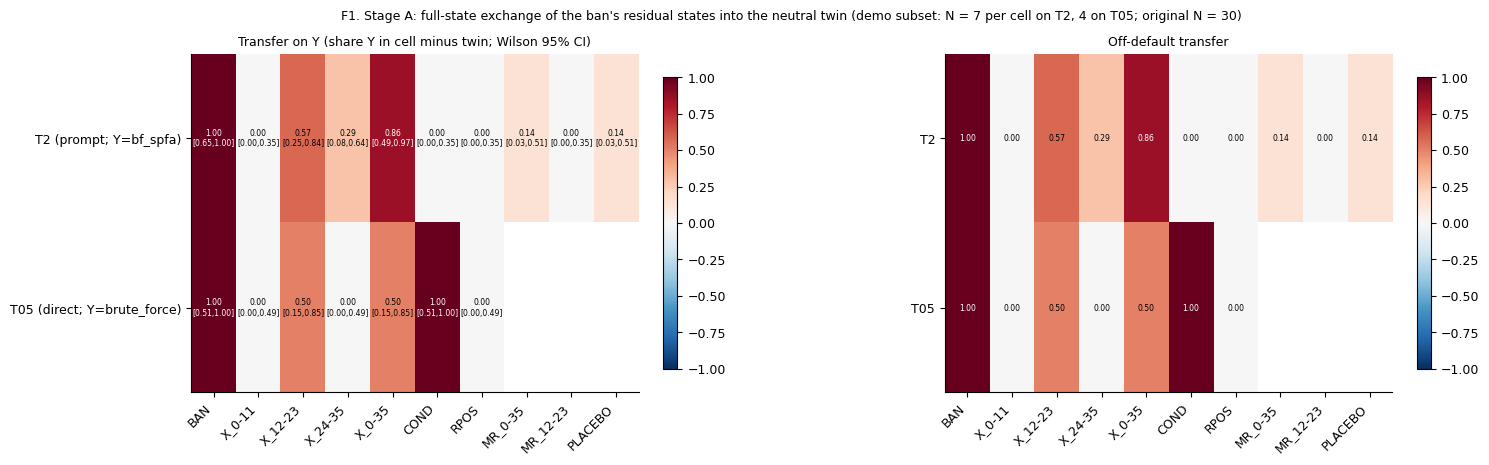

09:29:05|INFO   |figure F1_stageA_transfer


In [13]:
OI = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#999999"]
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})


def save(fig: plt.Figure, name: str) -> None:
    FIG_DIR.mkdir(exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()  # notebook: show inline before closing
    plt.close(fig)
    logger.info(f"figure {name}")


def f1() -> None:
    p = RESULTS_DIR / "stage_a.json"
    if not p.exists():
        return
    a = read_json(p)["tasks"]
    tasks = [t for t in ("T2", "T03", "T10", "T1", "T05", "T06") if t in a]
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={"wspace": 0.55})
    for ax, key, title in ((axes[0], "transfer", "Transfer on Y (share Y in cell minus twin; Wilson 95% CI)"),
                           (axes[1], "off_default_transfer", "Off-default transfer")):
        M = np.full((len(tasks), len(CELLS)), np.nan)
        for i, t in enumerate(tasks):
            for j, c in enumerate(CELLS):
                v = a[t]["cells"].get(c, {}).get(key)
                if v is not None:
                    M[i, j] = v
        im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
        for i, t in enumerate(tasks):
            for j, c in enumerate(CELLS):
                cc = a[t]["cells"].get(c)
                if cc is None:
                    continue
                txt = f"{M[i, j]:.2f}"
                if key == "transfer":
                    lo, hi = cc["Y_ci95_wilson"]
                    txt += f"\n[{lo - a[t]['TWIN']['Y_share']:.2f},{hi - a[t]['TWIN']['Y_share']:.2f}]"
                ax.text(j, i, txt, ha="center", va="center", fontsize=5.5,
                        color="white" if abs(M[i, j]) > 0.6 else "black")
        ax.set_xticks(range(len(CELLS)), CELLS, rotation=45, ha="right")
        ax.set_yticks(range(len(tasks)), [f"{t} ({a[t]['route_class_iter2_3']}; Y={a[t]['Y']})" if key == "transfer"
                                          else t for t in tasks])
        ax.set_title(title, fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.03)
    fig.suptitle("F1. Stage A: full-state exchange of the ban's residual states into the neutral twin "
                 "(demo subset: N = 7 per cell on T2, 4 on T05; original N = 30)", fontsize=9)
    save(fig, "F1_stageA_transfer")


f1()

# Part 2: the exchange itself, live at toy scale

Part 1 analysed programs that Qwen3-8B wrote on a GPU. Part 2 runs the **intervention code** that produced them, for one CRN slot of T2, on a model small enough for a CPU. Most of the code below is copied from `src/engine_v4.py`, `src/engine5.py` and `src/gpu6.py`; three cells are adapted for this notebook.

What differs from the original run, and why:
- **Model**: `Qwen/Qwen3-0.6B` (28 blocks, d_model 1024) instead of Qwen3-8B (36 blocks, 4096), to fit a 10-minute CPU budget. The Qwen3 family shares one tokenizer, so the **recorded prompt token ids and positions** (`prompts6.jsonl`, shipped in `mini_demo_data.json`) are used as they are.
- **Bands**: `BANDS` keep their names (`0-11`, `12-23`, `24-35`, `0-35` = first, middle and last third, and all blocks). They are re-derived for the loaded model's depth, which leaves them unchanged for a 36-block model.
- **N and length**: `LIVE_SLOTS` slot(s) instead of 30, and `LIVE_MAX_NEW` generated tokens instead of 512. The algorithm decision shows up in a program's first lines: its import and its leading comment.
- **Decoding**: `decode6`'s Stage A path, with exp27's `BufLayer` KV buffer, unchanged except that the ST-only S3 branch is removed.

**How to read the result.** All arms sample with the **same uniform stream**. An arm whose next-token distributions equal the twin's therefore reproduces the twin's program token for token, and one that carries the ban's information follows the ban's program. The readout is the length of the prefix each arm shares with TWIN and with BAN. A 0.6B model need not route the ban the way the 8B model does, so Part 2 demonstrates the mechanism; it does not replicate the result.

### 2.1 Engine primitives (`src/engine_v4.py`, `src/engine5.py`)

These functions are copied as written:
- `block_hooks`: forward hooks on decoder blocks that **edit** a block's output (`edits`, a function `h -> h'`) and/or **capture** it (`capture`);
- `build_cache`: builds a DynamicCache from per-layer K/V;
- `u_stream`: a slot's uniform stream, seeded by `stable_seed(task, template, k)`. This is what makes the random numbers *common* across arms;
- `_inverse_cdf`: turns one uniform into one token by inverse CDF over the vocabulary, so equal distributions give equal tokens;
- `step_probs5`: float64 softmax at temperature T;
- `fence_closed`: the stop rule (a closed python code block);
- `BufLayer`: exp27's preallocated KV buffer, one per layer, which the decoder writes into in place.

`clear_act_cache` empties the FP8 activation cache of iteration 4, which is unused in bf16/fp32.

In [14]:
# ------------------------------------------------------------------------------------------------ src/engine_v4.py
# bench extractor (exp11 harness.FENCE_RE) and exp8 suite extractor (closed python block) -- exp16 engine.py
BENCH_FENCE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*?)```", re.S)
PATH_FENCE = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)```", re.S)


def fence_closed(text: str, kind: str) -> bool:
    if kind == "bench":
        return BENCH_FENCE.search(text) is not None
    m = PATH_FENCE.search(text)
    return bool(m and m.group(1).strip())


_TICK: dict[str, Any] = {}
_VLEN: dict[int, int] = {}


def vocab_len(tok: Any) -> int:
    """len(tok) once per tokenizer (len() of the HF fast tokenizer costs ~0.03 s per call)."""
    k = id(tok)
    if k not in _VLEN:
        _VLEN[k] = len(tok)
    return _VLEN[k]


def backtick_ids(tok: Any) -> torch.Tensor:
    """Boolean [V] mask of vocabulary ids whose text contains a backtick (cached per tokenizer)."""
    key = id(tok)
    if key not in _TICK:
        V = vocab_len(tok)
        toks = tok.convert_ids_to_tokens(list(range(V)))
        m = np.zeros(200_000, dtype=bool)  # padded past the lm_head's 151,936 rows (ids beyond the tokenizer: False)
        m[:V] = [(t is not None and '`' in t) for t in toks]
        _TICK[key] = torch.tensor(m)
    return _TICK[key]


_ACT_CACHE: dict[str, Any] = {"x": None, "xq": None, "xs": None}


def clear_act_cache() -> None:
    _ACT_CACHE.update(x=None, xq=None, xs=None)


def layers(model: Any) -> Any:
    return model.model.layers


# ------------------------------------------------------------------------------------------------ hooks
def _out_tensor(out: Any) -> torch.Tensor:
    return out[0] if isinstance(out, tuple) else out


def _replace_out(out: Any, h: torch.Tensor) -> Any:
    if isinstance(out, tuple):
        return (h,) + tuple(out[1:])
    return h


@contextlib.contextmanager
def block_hooks(model: Any, edits: dict[int, Callable[[torch.Tensor], torch.Tensor]] | None = None,
                capture: dict[int, Callable[[torch.Tensor], None]] | None = None) -> Iterator[None]:
    """edits: {block: f(h) -> h'} applied to the block OUTPUT (in place on a clone); capture: {block: g(h)} called
    after the edit. Hooks are removed on exit."""
    hs = []
    edits = edits or {}
    capture = capture or {}
    for l in sorted(set(edits) | set(capture)):
        def hook(mod, inp, out, l=l):
            h = _out_tensor(out)
            if l in edits:
                h = edits[l](h)
                out = _replace_out(out, h)
            if l in capture:
                capture[l](h)
            return out
        hs.append(layers(model)[l].register_forward_hook(hook))
    try:
        yield
    finally:
        for h in hs:
            h.remove()


# ------------------------------------------------------------------------------------------------ caches
def _kv_list(cache: Any) -> list[tuple[torch.Tensor, torch.Tensor]]:
    if hasattr(cache, "layers"):
        return [(L.keys, L.values) for L in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))


def build_cache(kv: list[tuple[torch.Tensor, torch.Tensor]]):
    from transformers.cache_utils import DynamicCache

    cache = DynamicCache()
    for l, (K, V) in enumerate(kv):
        cache.update(K.contiguous(), V.contiguous(), l)
    return cache


# ------------------------------------------------------------------------------------------------ sampling
def u_stream(*key: Any, n: int = MAX_NEW_TOKENS) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def _inverse_cdf(probs: torch.Tensor, u: torch.Tensor) -> torch.Tensor:
    cdf = probs.cumsum(dim=-1)
    cdf = cdf / cdf[:, -1:]
    tok = torch.searchsorted(cdf, u[:, None].to(cdf.dtype)).squeeze(-1)
    return tok.clamp_(max=probs.shape[-1] - 1)


# ------------------------------------------------------------------------------------------------ src/engine5.py
def step_probs5(logits: torch.Tensor, T_t: torch.Tensor, top_k_t: torch.Tensor, top_p_t: torch.Tensor,
                any_topk: bool, any_topp: bool) -> torch.Tensor:
    """float64 probabilities: softmax(logits / T_row), then top-k (rows with k > 0) and top-p (rows with p < 1) masks.
    Masked mass is removed, not renormalised here (_inverse_cdf divides by the row total), so a row with T = 1,
    k = 0, p = 1 is exactly exp17's softmax(logits)."""
    probs = torch.softmax(logits / T_t, dim=-1)
    if any_topk:
        K_max = int(top_k_t.max().item())
        kth = probs.topk(K_max, dim=-1).values.gather(-1, (top_k_t.clamp(min=1) - 1)[:, None])
        probs = torch.where((top_k_t > 0)[:, None] & (probs < kth), torch.zeros_like(probs), probs)
    if any_topp:
        sp, si = probs.sort(dim=-1, descending=True)
        cum = sp.cumsum(-1)
        tot = cum[:, -1:]
        keep_sorted = (cum - sp) < top_p_t[:, None] * tot
        keep = torch.zeros_like(keep_sorted).scatter(-1, si, keep_sorted)
        probs = torch.where((top_p_t < 1.0)[:, None] & ~keep, torch.zeros_like(probs), probs)
    return probs


class BufLayer:
    """exp19 PreallocLayer built directly on a preallocated [B, H, Lmax, D] buffer (no second copy)."""

    is_sliding = False
    is_compileable = False

    def __init__(self, kbuf: torch.Tensor, vbuf: torch.Tensor, n: int):
        self.kbuf, self.vbuf, self.n = kbuf, vbuf, n
        self.dtype, self.device = kbuf.dtype, kbuf.device
        self.is_initialized = True
        self.keys, self.values = kbuf[:, :, :n], vbuf[:, :, :n]

    def lazy_initialization(self, key_states: torch.Tensor) -> None:
        return None

    def update(self, key_states, value_states, cache_kwargs=None):
        q = key_states.shape[-2]
        self.kbuf[:, :, self.n:self.n + q] = key_states
        self.vbuf[:, :, self.n:self.n + q] = value_states
        self.n += q
        self.keys, self.values = self.kbuf[:, :, :self.n], self.vbuf[:, :, :self.n]
        return self.keys, self.values

    def get_mask_sizes(self, cache_position: torch.Tensor) -> tuple[int, int]:
        return self.n + cache_position.shape[0], 0

    def get_seq_length(self) -> int:
        return self.n

    def get_max_cache_shape(self) -> int:
        return -1


print("CRN stream of T2 slot 0 (first 5 uniforms):", np.round(u_stream("T2", *SLOT_MAP[0], n=1536)[:5], 4))

CRN stream of T2 slot 0 (first 5 uniforms): [0.4159 0.928  0.8621 0.3743 0.6205]


### 2.2 Load the model (adapted from `src/engine6.py`)

The original loader puts bf16 Qwen3-8B on a 16 GB GPU and keeps the 151,936 x 4,096 input-embedding table in CPU RAM, doing an exact row gather per lookup. The demo loader below is device-agnostic. On a CUDA GPU with native bf16 it loads in bf16, as in the original; on a CPU, or a GPU without native bf16 such as Colab's T4, it loads in fp32, because emulated bf16 matmuls are slow. The cell then:
- re-derives `N_LAYERS6`, `ALL_BLOCKS`, `D_MODEL` and `BANDS` from the loaded model (for Qwen3-8B they equal the `cfg6` values);
- checks that the tokenizer matches the one the recorded prompt ids were built with;
- decodes the T2 twin prompt and marks its positions: **spec** `[p1, spec_end)`, **cond** (where ban and twin differ) and **R** (the read position).

In [15]:
def load_model_bf16(model_id: str = MODEL_ID, revision: str | None = MODEL_REVISION):
    """engine6.load_model_bf16, device-agnostic for the demo: bf16 on a cuda:0 that supports it natively (the original
    path, without the CPU-resident embedding table that Qwen3-8B needs on a 16 GB card), else fp32 (CPU, or e.g. a
    Colab T4 without native bf16). Returns (tok, model, info)."""
    from transformers import AutoModelForCausalLM, AutoTokenizer

    t0 = time.time()
    kw = {"revision": revision} if revision else {}
    tok = AutoTokenizer.from_pretrained(model_id, **kw)
    dev = torch.device("cuda", 0) if torch.cuda.is_available() else torch.device("cpu")
    dtype = torch.bfloat16 if dev.type == "cuda" and torch.cuda.is_bf16_supported(including_emulation=False) \
        else torch.float32
    model = AutoModelForCausalLM.from_pretrained(model_id, dtype=dtype, attn_implementation="sdpa",
                                                 low_cpu_mem_usage=True, **kw)
    model.to(dev)
    gc.collect()
    model.eval()
    model.requires_grad_(False)
    info = {"precision": str(dtype).replace("torch.", ""), "device": str(dev), "n_layers": model.config.num_hidden_layers,
            "d_model": model.config.hidden_size, "load_seconds": round(time.time() - t0, 1)}
    logger.info(f"{model_id} loaded: {info}")
    return tok, model, info


torch.set_num_threads(TORCH_THREADS)
tok, model, info = load_model_bf16(LIVE_MODEL_ID, LIVE_REVISION)

# the live model's geometry; for Qwen3-8B (36 blocks, d_model 4096) these equal the cfg / cfg6 values above
BANDS_36 = dict(BANDS)
N_LAYERS6 = model.config.num_hidden_layers
ALL_BLOCKS = list(range(N_LAYERS6))
D_MODEL = model.config.hidden_size
BANDS = {b: list(range(round(bl[0] * N_LAYERS6 / 36), round((bl[-1] + 1) * N_LAYERS6 / 36))) for b, bl in BANDS_36.items()}
print("bands (name -> blocks of the live model):", {b: f"{bl[0]}-{bl[-1]}" for b, bl in BANDS.items()})

# the recorded prompt ids were built with Qwen3-8B's tokenizer, which the whole Qwen3 family shares
assert tok.convert_tokens_to_ids("<|im_end|>") == IM_END and tok.decode([198]) == "\n"
P6 = {tuple(k.split("|")): v for k, v in data["metadata"]["prompts"].items()}   # prompts6.load_prompts6()
_tw = P6[(LIVE_TASK, SLOT_MAP[LIVE_SLOTS[0]][0], "twin")]
_bn = P6[(LIVE_TASK, SLOT_MAP[LIVE_SLOTS[0]][0], "ban")]
print(f"\n{LIVE_TASK} twin prompt ({_tw['P']} tokens):\n" + tok.decode(_tw["ids"]))
print("cond span  twin:", repr(tok.decode(_tw["ids"][_tw["cond"][0]:_tw["cond"][1]])),
      "| ban:", repr(tok.decode(_bn["ids"][_bn["cond"][0]:_bn["cond"][1]])))
print("spec span starts:", repr(tok.decode(_tw["ids"][_tw["p1"]:_tw["p1"] + 12])), "... ends:",
      repr(tok.decode(_tw["ids"][_tw["spec_end"] - 8:_tw["spec_end"]])), "| R token:", repr(tok.decode(_tw["ids"][_tw["R"]:])))
assert [i for i, (x, y) in enumerate(zip(_tw["ids"], _bn["ids"])) if x != y] == list(range(*_tw["cond"]))

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


09:29:11|INFO   |Qwen/Qwen3-0.6B loaded: {'precision': 'float32', 'device': 'cpu', 'n_layers': 28, 'd_model': 1024, 'load_seconds': 4.6}


bands (name -> blocks of the live model): {'0-11': '0-8', '12-23': '9-18', '24-35': '19-27', '0-35': '0-27'}

T2 twin prompt (200 tokens):
<|im_start|>user
Do not use man and the house for this task.

Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most 600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.<|im_end|>
<|im_start|>assistant
<think>

</think>


cond span  twin: ' man and the house' | ban: " Dijkstra's algorithm

### 2.3 Prompts, captures and the exchange edit (`src/gpu6.py`)

The original Stage A building blocks:
- `prefill6`: a batch-1 prompt pass under optional block edits. It returns the per-layer K/V, the read-position logits `r_logits` and the prompt length `P`.
- `assemble6`: stacks the per-row prefills of one prompt length into the batch's `BufLayer` buffers.
- `Prompt`: one (task, template, kind) prompt with its positions. It prefills once, cleanly, and captures **every block's output** at `[spec..., R, cond...]`.
- `set_rows_edit`: **the exchange**. At block *l*, the outputs at positions `pos` are overwritten with the source prompt's captured values.
- `mr_prefill`: the matched-norm random control, `h <- h_twin + ||h_ban - h_twin|| u`, with a fresh unit vector `u` per (slot, block, position).
- `TaskW`: holds the twin / ban / placebo prompts of one (task, template) and asserts that their positions coincide. Its ban-free noise unit `n`, which needs exp23's `r_Q` table, serves only the ST grid and is left out.

In [16]:
# ------------------------------------------------------------------------------------------------ helpers
def dev_of(model: Any) -> torch.device:
    return model.lm_head.weight.device


def code_stream(task: str, slot: int) -> np.ndarray:
    w, k = SLOT_MAP[slot]
    return u_stream(task, w, k, n=1536)


@torch.no_grad()
def prefill6(model: Any, ids: list[int], edits: dict | None = None, capture: dict | None = None) -> dict[str, Any]:
    """engine_v4.prefill with the KV moved to the CPU (assemble_cache copies it into the batch buffer)."""
    from transformers.cache_utils import DynamicCache

    inp = torch.tensor([ids], device=dev_of(model))
    cache = DynamicCache()
    clear_act_cache()
    with block_hooks(model, edits, capture):
        out = model.model(input_ids=inp, past_key_values=cache, use_cache=True)
    r_logits = model.lm_head(out.last_hidden_state[:, -1]).float()[0]
    kv = [(K.to("cpu"), V.to("cpu")) for K, V in _kv_list(cache)]
    del cache, out
    clear_act_cache()
    return {"kv": kv, "r_logits": r_logits, "P": len(ids)}


def assemble6(rows: list[dict[str, Any]], max_steps: int, dev: torch.device):
    """exp27 assemble_cache for rows of one prompt length, with the buffer always on the GPU (prefill KVs live on
    the CPU); rows sharing a prefill object are copied to the GPU once per layer."""
    from transformers.cache_utils import Cache

    P = rows[0]["pre"]["P"]
    assert all(r["pre"]["P"] == P for r in rows)
    B = len(rows)
    K0 = rows[0]["pre"]["kv"][0][0]
    _, H, _, D = K0.shape
    L = P + max_steps + 1
    layers_ = []
    for l in range(len(rows[0]["pre"]["kv"])):
        kb = torch.zeros(B, H, L, D, dtype=K0.dtype, device=dev)
        vb = torch.zeros_like(kb)
        g: dict[int, tuple[torch.Tensor, torch.Tensor]] = {}
        for i, r in enumerate(rows):
            key = id(r["pre"])
            if key not in g:
                K, V = r["pre"]["kv"][l]
                g[key] = (K[0].to(dev), V[0].to(dev))
            kb[i, :, :P] = g[key][0]
            vb[i, :, :P] = g[key][1]
        del g
        layers_.append(BufLayer(kb, vb, P))
    return Cache(layers=layers_), P


def cap_hooks(store: dict[int, torch.Tensor], idx: torch.Tensor, blocks: list[int]) -> dict[int, Callable]:
    """Capture block outputs (model dtype, exact) at positions idx for the given blocks."""
    def mk(l: int) -> Callable:
        def g(h: torch.Tensor) -> None:
            store[l] = h[0, idx].clone()
        return g
    return {l: mk(l) for l in blocks}


class Prompt:
    """One (task, template, kind) prompt with its positions and the clean prefill (+ captured states)."""

    def __init__(self, model: Any, rec: dict[str, Any], capture: bool = True):
        self.rec = rec
        self.ids = rec["ids"]
        self.P, self.p1, self.se = rec["P"], rec["p1"], rec["spec_end"]
        self.R = self.P - 1
        dev = dev_of(model)
        c = rec.get("cond") or [self.p1, self.p1]
        self.c0, self.c1 = c
        # index layout of captured states: [spec..., R, cond...]
        self.idx = torch.tensor(list(range(self.p1, self.se)) + [self.R] + list(range(self.c0, self.c1)), device=dev)
        self.nS = self.se - self.p1
        self.iS = slice(0, self.nS)
        self.iR = self.nS
        self.iC = slice(self.nS + 1, self.nS + 1 + (self.c1 - self.c0))
        self.H: dict[int, torch.Tensor] = {}
        self.pre = prefill6(model, self.ids, capture=cap_hooks(self.H, self.idx, ALL_BLOCKS) if capture else None)


# ------------------------------------------------------------------------------------------------ edits
def set_rows_edit(pos: torch.Tensor, src: dict[int, torch.Tensor]) -> dict[int, Callable]:
    """Exchange: overwrite block-l outputs at positions pos with src[l] (exact source values)."""
    def mk(l: int) -> Callable:
        def f(h: torch.Tensor) -> torch.Tensor:
            h = h.clone()
            h[0, pos] = src[l].to(h.dtype)
            return h
        return f
    return {l: mk(l) for l in src}


# ------------------------------------------------------------------------------------------------ contexts
class TaskW:
    """Per (task, template): twin / ban / placebo prompts with all-block captures at spec, R and cond."""

    def __init__(self, model: Any, P6: dict, task: str, w: str, kinds: tuple[str, ...] = ("twin", "ban")):
        self.model, self.task, self.w = model, task, w
        self.pr = {k: Prompt(model, P6[(task, w, k)]) for k in kinds}
        tw = self.pr["twin"]
        for k, p in self.pr.items():
            assert p.P == tw.P and p.p1 == tw.p1 and p.se == tw.se, f"{task}/{w}/{k}: positions differ from the twin"
        # (the ban-free unit self.n = ||h_twin|| * r_Q(l) of the ST grid is omitted: Stage A does not use it)

    def free(self) -> None:
        for p in self.pr.values():
            p.H.clear()
        self.pr.clear()
        gc.collect()
        torch.cuda.empty_cache()


def mr_prefill(model: Any, ctx: TaskW, task: str, band: str, slot: int) -> tuple[dict, dict]:
    """MR_b: h <- h_twin + ||h_src - h_twin||_(l,p) * u_(slot,l,p) at spec positions of band b (u fresh per (l, p))."""
    tw, bn = ctx.pr["twin"], ctx.pr["ban"]
    blocks = BANDS[band]
    seed = dir_seed(task, f"MR_{band}", 0, slot)
    g = np.random.Generator(np.random.PCG64(seed))
    X = g.standard_normal((len(blocks), tw.nS, D_MODEL), dtype=np.float32)
    X /= np.linalg.norm(X, axis=-1, keepdims=True)
    Xt = torch.from_numpy(X).to(dev_of(model))
    src = {}
    for j, l in enumerate(blocks):
        ht = tw.H[l][tw.iS].float()
        d = (bn.H[l][tw.iS].float() - ht).norm(dim=-1)
        src[l] = ht + d[:, None] * Xt[j]
    pre = prefill6(model, tw.ids, edits=set_rows_edit(tw.idx[tw.iS], src))
    del Xt, src
    return pre, {"dir_seed": seed}

### 2.4 CRN decoding (adapted from `src/gpu6.py: decode6`)

All arms of a slot decode **in one batch**. Every row brings its own prefill (its own K/V and read-position logits). All rows have the same prompt length, because the twins are token-length matched, so no padding or attention mask is needed: this is exp27's *shared path*. At each step the loop:
1. computes float64 softmax probabilities at T = 1 (`step_probs5`, no top-k/top-p);
2. draws **one uniform per (row, step) from the row's CRN stream** and inverts the CDF;
3. stops a row at `<|im_end|>` or once its text holds a closed ```` ```python ```` fence (checked every 8 steps on rows that produced a backtick);
4. keeps feeding finished rows `<|im_end|>`, so the batch shape stays constant.

The only change to the original: the S3 decode-time noise branch is removed (only the ST grid uses it). The KV buffer is exp27's own `BufLayer` through `assemble6`; it works unchanged under transformers 5.0.

In [17]:
@torch.no_grad()
def decode6(model: Any, rows: list[dict[str, Any]], tok: Any, fence_kind: str | None,
            check_every: int = 8) -> list[dict[str, Any]]:
    """exp27 engine5.decode_rows (shared path: every row has the same prompt length) for the Stage A arms; the S3
    decode-time noise site of the ST grid (s3=..., hooked/shadow row pairs) is left out."""
    dev = dev_of(model)
    B = len(rows)
    max_new = [int(r["max_new"]) for r in rows]
    max_steps = max(max_new)
    Ps = {r["pre"]["P"] for r in rows}
    assert len(Ps) == 1, "decode6: all rows must share the prompt length"
    cache, Pmax = assemble6(rows, max_steps, dev)
    Pvec = torch.full((B,), Pmax, dtype=torch.long, device=dev)
    Ucode = torch.zeros(B, max_steps, dtype=torch.float64, device=dev)
    for i, r in enumerate(rows):
        Ucode[i, :max_new[i]] = torch.from_numpy(np.asarray(r["u"], dtype=np.float64)[:max_new[i]])
    T_code = torch.tensor([float(r["T"]) for r in rows], dtype=torch.float64, device=dev)
    T_early = torch.tensor([float(r.get("T_early") if r.get("T_early") is not None else r["T"]) for r in rows],
                           dtype=torch.float64, device=dev)
    n_early = torch.tensor([int(r.get("n_early") or 0) for r in rows], dtype=torch.long, device=dev)
    zeros_l = torch.zeros(B, dtype=torch.long, device=dev)
    ones_p = torch.ones(B, dtype=torch.float64, device=dev)
    maxnew_t = torch.tensor(max_new, dtype=torch.long, device=dev)
    fence_rows = torch.tensor([bool(r.get("fence", True)) for r in rows], device=dev)
    i_code = torch.zeros(B, dtype=torch.long, device=dev)
    tick = backtick_ids(tok).to(dev) if fence_kind else None
    logits = torch.stack([r["pre"]["r_logits"] for r in rows], 0).double()
    toks = torch.full((B, max_steps), -1, dtype=torch.long, device=dev)
    lps = torch.zeros((B, max_steps), dtype=torch.float64, device=dev)
    done = torch.zeros(B, dtype=torch.bool, device=dev)
    ended = torch.zeros(B, dtype=torch.bool, device=dev)
    fenced = torch.zeros(B, dtype=torch.bool, device=dev)
    im_end_t = torch.full((B,), IM_END, dtype=torch.long, device=dev)
    ar = torch.arange(B, device=dev)
    host_toks: list[list[int]] = [[] for _ in range(B)]
    last_sync = 0
    step = 0
    while True:
        T_eff = torch.where(i_code < n_early, T_early, T_code)
        probs = step_probs5(logits, T_eff[:, None], zeros_l, ones_p, False, False)
        u = Ucode[ar, i_code.clamp(max=max_steps - 1)]
        nxt = _inverse_cdf(probs, u)
        plp = torch.log(probs.gather(-1, nxt[:, None])[:, 0])
        live = ~done
        i_code += live.long()
        toks[:, step] = torch.where(live, nxt, toks[:, step])
        lps[:, step] = torch.where(live, plp, lps[:, step])
        is_end = (nxt == IM_END) | (nxt == ENDOFTEXT)
        ended |= live & is_end
        done |= is_end | (live & (i_code >= maxnew_t))
        if step + 1 >= max_steps:
            break
        if (step + 1) % check_every == 0:
            if tick is not None:
                chunk = toks[:, last_sync:step + 1]
                has_tick = (tick[chunk.clamp(min=0)] & (chunk >= 0)).any(dim=1) & ~done & fence_rows
                chunk_c = chunk.cpu().numpy()
                for r_ in range(B):
                    host_toks[r_].extend(int(t) for t in chunk_c[r_] if t >= 0)
                last_sync = step + 1
                cand = torch.nonzero(has_tick).flatten().tolist()
                if cand:
                    nv = vocab_len(tok)
                    newly = [r_ for r_ in cand if fence_closed(
                        tok.decode([t for t in host_toks[r_] if t < nv], skip_special_tokens=True), fence_kind)]
                    if newly:
                        idx = torch.tensor(newly, device=dev)
                        fenced[idx] = True
                        done[idx] = True
            if bool(done.all().item()):
                break
        feed = torch.where(done, im_end_t, nxt)[:, None]
        pos = (Pvec + step)[:, None]
        clear_act_cache()
        h = model.model(input_ids=feed, past_key_values=cache, position_ids=pos, use_cache=True).last_hidden_state
        logits = model.lm_head(h[:, -1]).double()
        step += 1
    clear_act_cache()
    del cache
    toks_c, lps_c = toks.cpu().numpy(), lps.cpu().numpy()
    ended_c, fenced_c = ended.cpu().numpy(), fenced.cpu().numpy()
    out = []
    for r_ in range(B):
        row = toks_c[r_]
        n = int((row >= 0).sum())
        fr = "stop" if ended_c[r_] else ("fence" if fenced_c[r_] else "length")
        out.append({"token_ids": [int(t) for t in row[:n]], "finish_reason": fr, "n_tokens": n,
                    "logprob_sum": float(lps_c[r_, :n].sum()), "steps": step + 1})
    return out

### 2.5 Build the Stage A arms and decode them (from `src/gpu6.py: stage_twins_A`)

For each live slot, the cell below builds every arm's prefill with the original code of `stage_twins_A`:
- `TWIN` / `BAN`: the clean prefills of the two prompts (all-block captures included);
- `X_b`: a twin prefill under `set_rows_edit(spec_pos, ban states at band b)`;
- `COND`: the twin prefill's K/V with the condition span `[c0, c1)` replaced by the ban's in every layer. Its read-position logits stay the twin's, because only later tokens attend to the spliced span;
- `RPOS`: a twin prefill with the ban's read-position states at all blocks;
- `PLACEBO`: the twin with a *second neutral twin's* spec states (all blocks);
- `MR_b`: the twin under the matched-norm random edit (`mr_prefill`).

As a check, the cell first runs the original **U2** identity exchange from `stage_utest`: it writes the twin's own spec states back at every block, which must reproduce the clean twin exactly, with a K/V and logit difference of 0.

The arms then decode in one CRN batch. The original batched them in fixed shapes (`BATCH6`) through `run_batches`; this notebook decodes one batch per slot holding every arm. The result keeps `emit`'s fields: text, token ids, finish reason.

In [18]:
live: dict[int, dict[str, dict[str, Any]]] = {}     # slot -> arm -> emitted row
t_live0 = time.time()
task = LIVE_TASK
nv = vocab_len(tok)
for w in dict.fromkeys(SLOT_MAP[s][0] for s in LIVE_SLOTS):   # the templates of the live slots, in order
    t0 = time.time()
    kinds = ("twin", "ban", "placebo") if task in ("T03", "T10", "T2") else ("twin", "ban")
    ctx = TaskW(model, P6, task, w, kinds)
    tw, bn = ctx.pr["twin"], ctx.pr["ban"]
    pres: dict[str, dict[str, Any]] = {"TWIN": tw.pre, "BAN": bn.pre}
    spec_pos = tw.idx[tw.iS]
    # U2 (stage_utest): the identity exchange -- the twin's own spec states written back at every block -- must
    # reproduce the clean twin exactly (KV and read-position logits)
    pre_id = prefill6(model, tw.ids, edits=set_rows_edit(spec_pos, {l: tw.H[l][tw.iS] for l in ALL_BLOCKS}))
    u2 = max(float((x - y).abs().max()) for (Kx, Vx), (Ky, Vy) in zip(pre_id["kv"], tw.pre["kv"])
             for x, y in ((Kx, Ky), (Vx, Vy)))
    logger.info(f"U2 identity exchange {task}/{w}: max |dK, dV| = {u2:.1e}, max |d logit at R| = "
                f"{float((pre_id['r_logits'] - tw.pre['r_logits']).abs().max()):.1e}")
    for b, blocks in BANDS.items():
        pres[f"X_{b}"] = prefill6(model, tw.ids, edits=set_rows_edit(spec_pos, {l: bn.H[l][bn.iS] for l in blocks}))
    # COND: twin prefill, then the condition span's K/V in every layer replaced by the ban's
    kv = []
    for l in range(len(tw.pre["kv"])):
        K, V = tw.pre["kv"][l][0].clone(), tw.pre["kv"][l][1].clone()
        K[:, :, tw.c0:tw.c1] = bn.pre["kv"][l][0][:, :, tw.c0:tw.c1]
        V[:, :, tw.c0:tw.c1] = bn.pre["kv"][l][1][:, :, tw.c0:tw.c1]
        kv.append((K, V))
    pres["COND"] = {"kv": kv, "r_logits": tw.pre["r_logits"], "P": tw.P}
    pres["RPOS"] = prefill6(model, tw.ids, edits=set_rows_edit(tw.idx[tw.iR:tw.iR + 1],
                                                              {l: bn.H[l][tw.iR:tw.iR + 1] for l in ALL_BLOCKS}))
    if task in ("T03", "T10", "T2"):
        pl = ctx.pr["placebo"]
        pres["PLACEBO"] = prefill6(model, tw.ids, edits=set_rows_edit(spec_pos, {l: pl.H[l][pl.iS]
                                                                                for l in ALL_BLOCKS}))
    logger.info(f"{task}/{w}: {len(pres)} template-level prefills in {time.time() - t0:.1f}s")
    for s in [s for s in LIVE_SLOTS if SLOT_MAP[s][0] == w]:
        t1 = time.time()
        arm_pre = dict(pres)
        if task in ("T03", "T10", "T2"):
            for b in ("0-35", "12-23"):
                arm_pre[f"MR_{b}"], _ = mr_prefill(model, ctx, task, b, s)   # fresh directions per slot
        arms = [arm for arm in LIVE_ARMS if arm in arm_pre]
        rows_live = [{"pre": arm_pre[arm], "u": code_stream(task, s), "T": 1.0, "max_new": LIVE_MAX_NEW,
                      "fence": True} for arm in arms]
        res = decode6(model, rows_live, tok, fence6(task))
        live[s] = {arm: {"arm": arm, "slot_index": s, "template": w, "slot": SLOT_MAP[s][1],
                         "text": tok.decode([t for t in r["token_ids"] if t < nv], skip_special_tokens=True),
                         "token_ids": r["token_ids"], "n_new_tokens": r["n_tokens"],
                         "finish_reason": r["finish_reason"], "logprob_sum": r["logprob_sum"]}
                   for arm, r in zip(arms, res)}
        logger.info(f"{task} slot {s}: {len(arms)} arms x {res[0]['steps']} steps decoded in {time.time() - t1:.1f}s")
    ctx.free()
print(f"live Stage A replay: {time.time() - t_live0:.1f}s for {len(LIVE_SLOTS)} slot(s)")

09:29:18|INFO   |U2 identity exchange T2/W1: max |dK, dV| = 0.0e+00, max |d logit at R| = 0.0e+00


09:29:28|INFO   |T2/W1: 9 template-level prefills in 17.0s


09:30:28|INFO   |T2 slot 0: 11 arms x 128 steps decoded in 59.3s


09:31:28|INFO   |T2 slot 1: 11 arms x 128 steps decoded in 60.3s


live Stage A replay: 136.8s for 2 slot(s)


### 2.6 What the toy model wrote under each arm

The original run labelled every program with the frozen labellers, which run it against the test suite with a runtime tracer and AST rules. The toy programs here are cut at `LIVE_MAX_NEW` tokens, so the table reads them in two ways:
- **hint**: a demo-only keyword heuristic for the algorithm the program starts to write, for example `heapq` → Dijkstra-like, or a BFS `deque` / `Bellman`. This is the primary readout. It is **not** the artifact's labeller.
- **departure from BAN**: all arms draw the same uniform numbers, so an arm writes the same tokens as BAN until their next-token distributions differ enough to change a draw. The table gives the token index of that first difference and what BAN and the arm write there.

An early departure can be a near-tie, such as a blank line, which any perturbation flips, the random `MR` control included. A departure exactly where BAN names its algorithm means the arm copied the ban's surface but not its choice.

In [19]:
def shared_prefix(a_ids: list[int], b_ids: list[int]) -> int:
    """Number of leading generated tokens two CRN-paired arms have in common."""
    n = 0
    for x, y in zip(a_ids, b_ids):
        if x != y:
            break
        n += 1
    return n


def algorithm_hint(text: str) -> str:
    """Demo-only keyword hint for the toy model's (often unfinished) T2 programs -- NOT the frozen labeller."""
    s = text.lower()
    if "bellman" in s or "spfa" in s or "range(n - 1)" in s or "range(n-1)" in s:
        return "bellman-ford-like"
    if "heapq" in s or "heappush" in s or "heappop" in s:
        return "dijkstra-like (heap)"
    if "dijkstra" in s:
        return "mentions dijkstra"
    if "deque" in s or "bfs" in s or "popleft" in s or "pop(0)" in s:
        return "bfs-like"
    if "lambda" in s and "def " not in s:
        return "one-line stub"
    return "undetermined"


live_summary = []
for s, arms_out in live.items():
    tw_ids, bn_ids = arms_out["TWIN"]["token_ids"], arms_out["BAN"]["token_ids"]
    for arm, r in arms_out.items():
        k = shared_prefix(r["token_ids"], bn_ids)
        live_summary.append({"slot": s, "arm": arm, "n_tokens": r["n_new_tokens"], "finish": r["finish_reason"],
                             "hint": algorithm_hint(r["text"]),
                             "shared_with_TWIN": shared_prefix(r["token_ids"], tw_ids), "shared_with_BAN": k,
                             "BAN_writes": tok.decode(bn_ids[k:k + 5]) if arm != "BAN" else "",
                             "arm_writes": tok.decode(r["token_ids"][k:k + 5]) if arm != "BAN" else ""})
md = ["| slot | arm | hint (keywords) | tokens | shared with TWIN | departs from BAN at token | BAN writes | arm writes |",
      "|---|---|---|---|---|---|---|---|"]
for x in live_summary:
    dep = "-" if x["arm"] == "BAN" else (x["shared_with_BAN"] if x["shared_with_BAN"] < x["n_tokens"] else "never")
    md.append(f"| {x['slot']} | {x['arm']} | {x['hint']} | {x['n_tokens']} | {x['shared_with_TWIN']} | {dep} | "
              f"{x['BAN_writes']!r} | {x['arm_writes']!r} |".replace("''", "-"))
display(Markdown("\n".join(md)))
print("hint per arm and slot:", {(x["slot"], x["arm"]): x["hint"] for x in live_summary})

for s, arms_out in live.items():
    for arm in ("TWIN", "BAN", "X_0-35", "COND"):
        if arm in arms_out:
            print(f"\n===== {LIVE_MODEL_ID} | {LIVE_TASK} slot {s} | {arm} ({arms_out[arm]['n_new_tokens']} tokens, "
                  f"{arms_out[arm]['finish_reason']})")
            print(arms_out[arm]["text"])

| slot | arm | hint (keywords) | tokens | shared with TWIN | departs from BAN at token | BAN writes | arm writes |
|---|---|---|---|---|---|---|---|
| 0 | TWIN | dijkstra-like (heap) | 128 | 128 | 30 | '    for u, v' | '    \n    for u,' |
| 0 | BAN | bfs-like | 128 | 30 | - | - | - |
| 0 | X_0-11 | dijkstra-like (heap) | 128 | 30 | 76 | ' a BFS approach to find' | " Dijkstra's algorithm\n" |
| 0 | X_12-23 | dijkstra-like (heap) | 128 | 30 | 76 | ' a BFS approach to find' | " Dijkstra's algorithm\n" |
| 0 | X_24-35 | dijkstra-like (heap) | 128 | 128 | 30 | '    for u, v' | '    \n    for u,' |
| 0 | X_0-35 | dijkstra-like (heap) | 128 | 30 | 76 | ' a BFS approach to find' | " Dijkstra's algorithm\n" |
| 0 | COND | dijkstra-like (heap) | 128 | 77 | 30 | '    for u, v' | '    \n    for u,' |
| 0 | RPOS | dijkstra-like (heap) | 128 | 128 | 30 | '    for u, v' | '    \n    for u,' |
| 0 | PLACEBO | dijkstra-like (heap) | 128 | 128 | 30 | '    for u, v' | '    \n    for u,' |
| 0 | MR_0-35 | dijkstra-like (heap) | 128 | 30 | 76 | ' a BFS approach to find' | " Dijkstra's algorithm\n" |
| 0 | MR_12-23 | dijkstra-like (heap) | 128 | 128 | 30 | '    for u, v' | '    \n    for u,' |
| 1 | TWIN | bfs-like | 128 | 128 | 3 | 'solve = lambda n,' | '```python\ndef solve' |
| 1 | BAN | one-line stub | 24 | 3 | - | - | - |
| 1 | X_0-11 | undetermined | 128 | 54 | 3 | 'solve = lambda n,' | '```python\ndef solve' |
| 1 | X_12-23 | one-line stub | 26 | 3 | 14 | ' ...  # Complete the' | ' solve_helper(n, edges' |
| 1 | X_24-35 | bfs-like | 128 | 128 | 3 | 'solve = lambda n,' | '```python\ndef solve' |
| 1 | X_0-35 | one-line stub | 26 | 3 | 14 | ' ...  # Complete the' | ' solve_helper(n, edges' |
| 1 | COND | bfs-like | 128 | 21 | 3 | 'solve = lambda n,' | '```python\ndef solve' |
| 1 | RPOS | bfs-like | 128 | 128 | 3 | 'solve = lambda n,' | '```python\ndef solve' |
| 1 | PLACEBO | bfs-like | 128 | 128 | 3 | 'solve = lambda n,' | '```python\ndef solve' |
| 1 | MR_0-35 | undetermined | 128 | 54 | 3 | 'solve = lambda n,' | '```python\ndef solve' |
| 1 | MR_12-23 | bfs-like | 128 | 128 | 3 | 'solve = lambda n,' | '```python\ndef solve' |

hint per arm and slot: {(0, 'TWIN'): 'dijkstra-like (heap)', (0, 'BAN'): 'bfs-like', (0, 'X_0-11'): 'dijkstra-like (heap)', (0, 'X_12-23'): 'dijkstra-like (heap)', (0, 'X_24-35'): 'dijkstra-like (heap)', (0, 'X_0-35'): 'dijkstra-like (heap)', (0, 'COND'): 'dijkstra-like (heap)', (0, 'RPOS'): 'dijkstra-like (heap)', (0, 'PLACEBO'): 'dijkstra-like (heap)', (0, 'MR_0-35'): 'dijkstra-like (heap)', (0, 'MR_12-23'): 'dijkstra-like (heap)', (1, 'TWIN'): 'bfs-like', (1, 'BAN'): 'one-line stub', (1, 'X_0-11'): 'undetermined', (1, 'X_12-23'): 'one-line stub', (1, 'X_24-35'): 'bfs-like', (1, 'X_0-35'): 'one-line stub', (1, 'COND'): 'bfs-like', (1, 'RPOS'): 'bfs-like', (1, 'PLACEBO'): 'bfs-like', (1, 'MR_0-35'): 'undetermined', (1, 'MR_12-23'): 'bfs-like'}

===== Qwen/Qwen3-0.6B | T2 slot 0 | TWIN (128 tokens, length)
```python
def solve(n, edges, s, t):
    # Create an adjacency list
    graph = [[] for _ in range(n)]
    
    for u, v, w in edges:
        graph[u].append((v, w))
    
    # Check

## Results: summary figure and table

- **Left and middle panels**: per cell, the share of recorded Qwen3-8B programs that land on the ban's substitute Y. Bars are the demo subset with Clopper-Pearson 95% intervals; diamonds are the full run with N = 30 per cell, shipped in `metadata.full_run_stage_a`; the dotted line is the twin.
- **Right panel**: the live toy replay. For each arm, the number of leading tokens it shares with the TWIN and with the BAN program under the same uniform stream.
- **Table**: the demo subset against the full run, cell by cell.

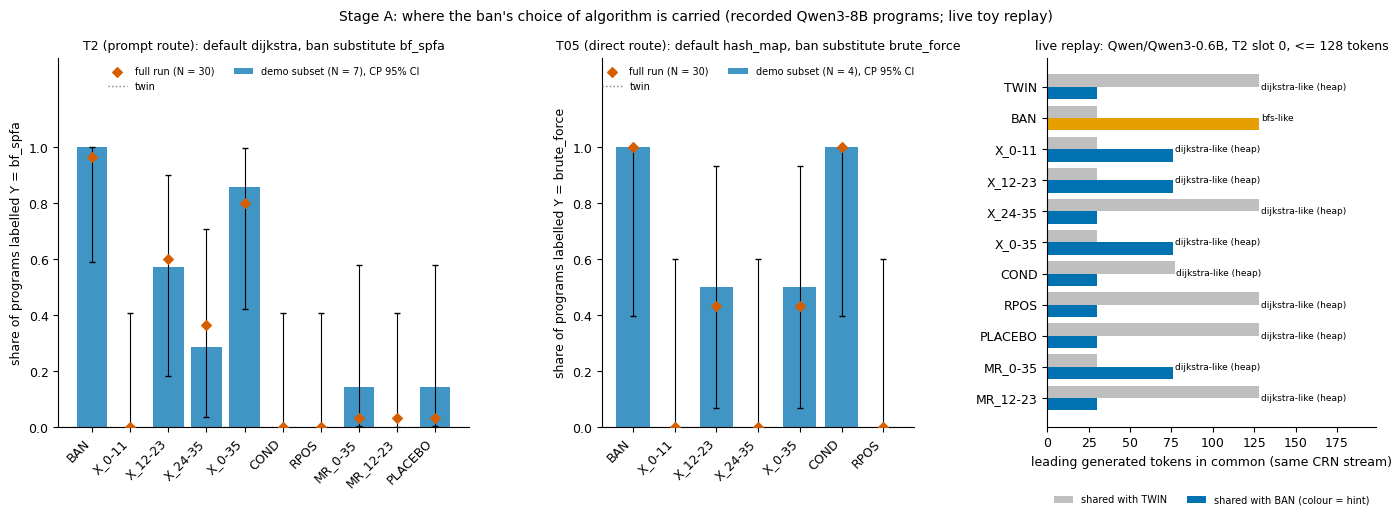

09:31:29|INFO   |figure demo_summary


| task | cell | demo n | demo Y share | demo transfer | demo McNemar b:c | full-run Y share | full-run transfer | full-run b:c |
|---|---|---|---|---|---|---|---|---|
| T2 | BAN | 7 | 1.00 | 1.00 | 7:0 | 0.97 | 0.97 | 29:0 |
| T2 | X_0-11 | 7 | 0.00 | 0.00 | 0:0 | 0.00 | 0.00 | 0:0 |
| T2 | X_12-23 | 7 | 0.57 | 0.57 | 4:0 | 0.60 | 0.60 | 18:0 |
| T2 | X_24-35 | 7 | 0.29 | 0.29 | 2:0 | 0.37 | 0.37 | 11:0 |
| T2 | X_0-35 | 7 | 0.86 | 0.86 | 6:0 | 0.80 | 0.80 | 24:0 |
| T2 | COND | 7 | 0.00 | 0.00 | 0:0 | 0.00 | 0.00 | 0:0 |
| T2 | RPOS | 7 | 0.00 | 0.00 | 0:0 | 0.00 | 0.00 | 0:0 |
| T2 | MR_0-35 | 7 | 0.14 | 0.14 | 1:0 | 0.03 | 0.03 | 1:0 |
| T2 | MR_12-23 | 7 | 0.00 | 0.00 | 0:0 | 0.03 | 0.03 | 1:0 |
| T2 | PLACEBO | 7 | 0.14 | 0.14 | 1:0 | 0.03 | 0.03 | 1:0 |
| T05 | BAN | 4 | 1.00 | 1.00 | 4:0 | 1.00 | 1.00 | 30:0 |
| T05 | X_0-11 | 4 | 0.00 | 0.00 | 0:0 | 0.00 | 0.00 | 0:0 |
| T05 | X_12-23 | 4 | 0.50 | 0.50 | 2:0 | 0.43 | 0.43 | 13:0 |
| T05 | X_24-35 | 4 | 0.00 | 0.00 | 0:0 | 0.00 | 0.00 | 0:0 |
| T05 | X_0-35 | 4 | 0.50 | 0.50 | 2:0 | 0.43 | 0.43 | 13:0 |
| T05 | COND | 4 | 1.00 | 1.00 | 4:0 | 1.00 | 1.00 | 30:0 |
| T05 | RPOS | 4 | 0.00 | 0.00 | 0:0 | 0.00 | 0.00 | 0:0 |

In [20]:
full = data["metadata"]["full_run_stage_a"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.25, 0.95, 1.0], "wspace": 0.38})
for ax, t in zip(axes[:2], DEMO_TASKS):
    cells_t = [c for c in CELLS if c in a["tasks"][t]["cells"]]
    x = np.arange(len(cells_t))
    ys = np.array([a["tasks"][t]["cells"][c]["Y_share"] for c in cells_t])
    ci = np.array([a["tasks"][t]["cells"][c]["Y_ci95_cp"] for c in cells_t])
    ax.bar(x, ys, color=OI[5], alpha=0.75, label=f"demo subset (N = {a['tasks'][t]['cells']['BAN']['n']}), CP 95% CI")
    ax.errorbar(x, ys, yerr=[ys - ci[:, 0], ci[:, 1] - ys], fmt="none", ecolor="k", capsize=2, lw=0.8)
    ax.scatter(x, [full[t]["cells"][c]["Y_share"] for c in cells_t], marker="D", color=OI[6], zorder=3, s=24,
               label="full run (N = 30)")
    ax.axhline(a["tasks"][t]["TWIN"]["Y_share"], color="grey", ls=":", lw=1, label="twin")
    ax.set_xticks(x, cells_t, rotation=45, ha="right")
    ax.set_ylim(0, 1.32)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_ylabel(f"share of programs labelled Y = {Y6[t]}")
    ax.set_title(f"{t} ({ROUTE_CLASS[t]} route): default {DEFAULT6[t]}, ban substitute {Y6[t]}", fontsize=9)
    ax.legend(fontsize=7, loc="upper center", ncol=2, frameon=False)
s0 = LIVE_SLOTS[0]
ls = [x for x in live_summary if x["slot"] == s0]
yy = np.arange(len(ls))
hint_col = {"dijkstra-like (heap)": OI[5], "mentions dijkstra": OI[5], "bfs-like": OI[1], "bellman-ford-like": OI[6],
            "one-line stub": OI[7], "undetermined": OI[8]}
axes[2].barh(yy - 0.2, [x["shared_with_TWIN"] for x in ls], height=0.4, color="0.75", label="shared with TWIN")
axes[2].barh(yy + 0.2, [x["shared_with_BAN"] for x in ls], height=0.4, color=[hint_col[x["hint"]] for x in ls],
             label="shared with BAN (colour = hint)")
for yv, x in zip(yy, ls):
    axes[2].text(max(x["shared_with_TWIN"], x["shared_with_BAN"]) + 1, yv, x["hint"], va="center", fontsize=6.5)
axes[2].set_yticks(yy, [x["arm"] for x in ls])
axes[2].invert_yaxis()
axes[2].set_xlim(0, LIVE_MAX_NEW * 1.55)
axes[2].set_xlabel("leading generated tokens in common (same CRN stream)")
axes[2].set_title(f"live replay: {LIVE_MODEL_ID}, {LIVE_TASK} slot {s0}, <= {LIVE_MAX_NEW} tokens", fontsize=9)
axes[2].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
fig.suptitle("Stage A: where the ban's choice of algorithm is carried (recorded Qwen3-8B programs; live toy replay)",
             fontsize=10)
save(fig, "demo_summary")

lines = ["| task | cell | demo n | demo Y share | demo transfer | demo McNemar b:c | full-run Y share | full-run transfer |"
         " full-run b:c |", "|---|---|---|---|---|---|---|---|---|"]
for t in DEMO_TASKS:
    for c in CELLS:
        if c not in a["tasks"][t]["cells"]:
            continue
        d, fr = a["tasks"][t]["cells"][c], full[t]["cells"][c]
        m = d["mcnemar_vs_twin"]
        lines.append(f"| {t} | {c} | {d['n']} | {f(d['Y_share'])} | {f(d['transfer'])} | "
                     f"{m['b_Y_only_cell']}:{m['c_Y_only_twin']} | {f(fr['Y_share'])} | {f(fr['transfer'])} | "
                     f"{fr['mcnemar_b_c'][0]}:{fr['mcnemar_b_c'][1]} |")
display(Markdown("\n".join(lines)))

## Takeaways

- **Where the choice is carried (recorded Qwen3-8B programs, Part 1).** A prompt ban does not just delete the default algorithm; the model substitutes another one, and it does so through one of **two routes**.
  - On the prompt-route task T2, the ban's information sits in the residual states of the **task-specification tokens**, mostly at the middle blocks. Copying only those states into the neutral prompt moves most CRN slots from Dijkstra to Bellman-Ford/SPFA, while splicing in the ban's own words (`COND`) or the read position (`RPOS`) moves none.
  - On the direct-route task T05, the generated code reads the ban's words directly: the condition-span splice alone reproduces the full ban.
  - Matched-norm random exchanges and a placebo twin barely move anything. The size of the perturbation is not what matters; the ban's information is.
- **Mechanism (Part 2).** The same capture → exchange → CRN-decode code runs on any Qwen3 model. The identity exchange (U2) reproduces the twin exactly, and the departure table shows, token by token, where each arm leaves the ban's program.
  - In the committed outputs (fp32 on an AMD EPYC CPU), every exchange arm of slot 0 keeps Dijkstra. The spec-state arms copy the ban's text up to the point where the ban names BFS, and the random `MR_0-35` copies it too, because that prefix comes from a near-tie. In slot 1, the toy model answers the ban with a one-line stub, and only the task-spec exchanges `X_12-23` and `X_0-35` reproduce that response.
  - The exact toy outputs can differ on another CPU, because float rounding flips near-tied tokens.
  - With 0.6B parameters and two slots, this replay illustrates the mechanism and is not evidence about the 8B model.
- **Full run.** `method.py all` in the artifact's repository repeats this for six tasks × 30 slots on Qwen3-8B, together with the ST noise grid, the state-vs-token contrast, the top-five push and the landing contest. That takes about 2.7 GPU-hours on a 16 GB GPU.